# E12-H68 - shared-source grounding-grid memoisation

**Author**: Konrad Jelen (kj)<br>
**Pipeline stage**: experiment - registered hypothesis E12-H68 of the E12 improvement fanout

Tests one pre-registered build over the source-conditioned path: a per-`DocDistance` memo keyed on
`(doc, source)` that caches the reranker relevance grid `R(doc, S)` and the NLI entailment vector
produced by `DocDistance._grounding` (`src/docdistance/pipeline.py:719-729`), together with the
`embed_statements` output each of them is built from.

`DocDistance.distance_wrt_source` (`src/docdistance/pipeline.py:838-871`) re-embeds `a`, `b` and
`source` and re-runs both grounding grids on every call. In an all-pairs sweep of `N` candidates
against one source, every document's grid is therefore recomputed `N-1` times: the 55-pair sweep of
the 11 IBM executive summaries pays 110 grid evaluations for 11 distinct `(doc, source)`
combinations. The reranker full grid is roughly 99% of the per-pair CPU INT8 cost
(`docs/solution/wmd-source-conditioned-docdistance-solution-sota.md:86`), so deduplicating it turns a
quadratic-in-`N` cross-encoder bill into a linear one.

Nothing under `src/` is modified. The memo is prototyped in this notebook as a class-level
monkeypatch of `DocDistance.embed_statements` plus a notebook-level replica of `distance_wrt_source`
that routes the two `_grounding` calls through an instance-scoped cache. The `--pairs` addition to
the `distance-wrt-source` command is a follow-up build and is deliberately not part of this
experiment; the batch loop is driven here in-process.

**Why this is a pure-caching change.** `_grounding` takes exactly `doc_sents` and `src_sents` and
returns `(R, entail)`; it never sees the other document of the pair and never sees the anisotropy
pre-pass. The embedding cache boundary is pinned *before* anisotropy removal, because
`all_but_the_top` (`src/docdistance/distance.py:94-115`) pools `a`, `b` and `source` jointly, so
anything cached after it would silently change scores. Below those two boundaries the work is a
deterministic function of file content, so a hit returns exactly what a miss would have computed.
The proof is therefore a byte diff, not a tolerance.

**Measured quantities**

- **wall time per sweep** - the warm sequential loop over one `DocDistance`, model load excluded
- **grounding-grid evaluations** - instrumented count of `_grounding` calls that reached the reranker and the entailer
- **byte diff** - exact `bytes` equality of each pair's `json.dumps(result.to_dict(), indent=2)` payload, the string the shipped `distance-wrt-source --json` prints
- **V** - ordinality violations on the `D_sel` anchor panel, out of 24; standing guardrail, must stay `0`

**Approach**

1. **Kill gate first**, before any build - *why*: the record kills the candidate if the intended
   sweeps carry no repeated `(doc, source)` combination, in which case only the model-load
   amortisation of a batch mode survives and that is seconds against a 58 s pair
2. **Memo prototype**, then the record's **pre-merge sanity check** - two instrumented runs on
   `(A,B|S)` and `(A,C|S)` diffing the two `R(A,S)` grids - *why*: the byte diff over 55 pairs can
   only be trusted if the grid is first shown to be a pure function of `(doc, source)`
3. **Four measured arms** - the 55-pair all-pairs sweep, a fragment-filter arm exercising the
   `n_dropped` restoration, a no-fanout control where every document appears once, and the
   anchor-fanout shape - *why*: the bar has a speed clause and a byte-identity clause and each sweep
   shape exercises a different reuse fraction
4. **Cold-CLI load amortisation, reported separately**, over a covering subset of the sweep -
   *why*: the record forbids folding the model-load saving of a batch mode into the claimed win,
   and re-scoring a subset through the shipped `distance-wrt-source --json` in a fresh subprocess
   is what makes the in-process byte diff a diff against the shipped command rather than against
   this notebook's own replica
5. **Guardrails, measured** - V, the default-path `smd` / `order_gap` bit-identity, the metric
   property of the selection axis, the `src/` byte diff
6. **Verdict** against the pre-registered acceptance bar, read literally

**Outputs**

- Kill-gate table, sanity-check table, memo-correctness table, per-arm timing and byte-diff table
- Wall-time and grid-count figures, and the per-pair cumulative-cost curve
- `reports/E12-H68-grounding-grid-memo-metrics.json`

## Environment

No GPU is used. The workstation's GPUs are held by foreign jobs, so `CUDA_VISIBLE_DEVICES` is pinned
empty before any torch import and all four models run on CPU: the `sat-3l-sm` segmenter, the mmBERT
OpenVINO INT8 encoder, the `bge-reranker-v2-m3` INT8 cross-encoder and the `mDeBERTa` INT8 entailer.
This hypothesis is a timing measurement, so the notebook runs alone on the workstation and every
timed sweep records the 1-minute load average immediately before it starts.

In [1]:
import os

os.environ["CUDA_VISIBLE_DEVICES"] = ""          # CPU pin - GPUs held by foreign jobs
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"

import warnings

warnings.filterwarnings("ignore")

import torch

DEVICE = "cpu"
print(f"torch {torch.__version__} | cuda visible: {torch.cuda.is_available()} | device: {DEVICE}")
print(f"cpu count: {os.cpu_count()} | load average (1m, 5m, 15m): {os.getloadavg()}")

torch 2.12.0+cu130 | cuda visible: False | device: cpu
cpu count: 64 | load average (1m, 5m, 15m): (4.27490234375, 5.4423828125, 7.3310546875)


## Imports

The shipped `docdistance` pipeline, its source-conditioned core and the CLI helper that builds the
`n_dropped` block of the machine JSON. `DocDistance.distance_wrt_source`,
`DocDistance._grounding` and `docdistance.distance.compute_source_conditioned` are imported, never
reimplemented, so the baseline arm and the memo arm run the same shipped code underneath.

In [2]:
%load_ext autoreload
%autoreload 2

# stdlib
import hashlib
import json
import random
import statistics
import subprocess
import sys
import time
from itertools import combinations
from pathlib import Path

# scientific
import numpy as np

# viz
import matplotlib.pyplot as plt
import seaborn as sns

# console
from rich.console import Console
from rich.panel import Panel
from rich.table import Table
from tqdm import tqdm

# display
from IPython.display import Markdown, display

# the shipped library
import ot
from docdistance import __version__ as DD_VERSION
from docdistance import config as dd_config
from docdistance import settings
from docdistance.cli import _drop_extra
from docdistance.distance import (
    SMD_MAX,
    compute_source_conditioned,
    coverage_profile,
    selection_divergence,
    smd,
)
from docdistance.pipeline import DocDistance

console = Console()
sns.set_theme(style="whitegrid", context="notebook")

LOGSTREAM = sys.__stderr__ or sys.stderr        # the kernel's real stderr - nbconvert tees it to the run log


def note(msg):
    # one line to the notebook and one to the run log, so a detached execution can be followed
    print(msg)
    print(msg, file=LOGSTREAM, flush=True)


def pbar(iterable, desc):
    return tqdm(iterable, desc=desc, file=LOGSTREAM, mininterval=5.0, leave=False)


note(f"imports ready | docdistance {DD_VERSION} | POT {ot.__version__} | "
     f"RERANK_TOP_K {dd_config.RERANK_TOP_K}")

imports ready | docdistance 1.1.5 | POT 0.9.7.post1 | RERANK_TOP_K 3


imports ready | docdistance 1.1.5 | POT 0.9.7.post1 | RERANK_TOP_K 3


## Reproducibility

Segmentation, the OpenVINO INT8 encode, the INT8 cross-encoder grid, the INT8 entailer and the
network-simplex EMD solve take no random input, so every number in this notebook is deterministic.
The seed is fixed anyway so the run is reproducible end to end; nothing here samples.

In [3]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
print(f"SEED={SEED}")

SEED=42


## Configuration

Paths, the sweep shapes, the kill gate and the acceptance bar, all read verbatim from the ledger
record `E12-H68`.

The **kill gate** is a counting exercise over the intended sweep specifications, run before any
build: if production sweeps are one pair per source - no candidate fanout - the memo hit rate is `0`
and only the model-load amortisation of a batch mode survives, which is seconds against a 58 s pair.
The death line is therefore a repeated-slot fraction of `0` across every intended sweep.

The **acceptance bar**, read literally: each of the 55 batch JSON payloads byte-identical to the
corresponding one-shot `distance-wrt-source --json` output, **AND** at least a `5x` wall-time
reduction against the warm-instance sequential baseline, **AND** a semantic / structural fixture
rerun confirming the default path's `smd` and `order_gap` are byte-identical with `V` at `0/24` and
the metric property preserved. FAIL if any per-pair number differs, or the end-to-end gain is under
`3x`.

Timing protocol, fixed here before any measurement: the headline sweep is a single interleaved
off/on pass, because one baseline pass over 55 pairs is already about 53 minutes of cross-encoder
work; the smaller arms are measured the same way, and off and on run back to back so any drift in
machine state falls on both.

The `8.0` load-average ceiling is a **foreign-load** precondition, read once with the notebook idle
before any sweep. It cannot be enforced between sweeps: this notebook saturates 64 threads with
INT8 cross-encoder work, so the 1-minute average immediately after a sweep is dominated by the
notebook's own residual load rather than by contention. Between sweeps the harness therefore settles
for at most 60 seconds and records the reading it took, whatever it is.

In [4]:
ROOT = Path("/home/lab/workspace/learning/projects/docdistance")
os.chdir(ROOT)                                   # the readiness gate resolves docdistance.json from cwd
os.environ["DOCDISTANCE_HOME"] = str(ROOT)

SUMMARY_DIR = ROOT / "data/interim/exec-summaries/ibm-ai-adoption/summaries"
IBM_SOURCE = ROOT / "data/interim/exec-summaries/ibm-ai-adoption/source/source-article.md"
H67_DIR = ROOT / "data/interim/E12-H67"          # registered sweep TSVs from the sibling hypothesis
WORK = ROOT / "data/interim/E12-H68"             # this hypothesis' sweep TSVs (gitignored)
REPORT = ROOT / "reports/E12-H68-grounding-grid-memo-metrics.json"

DOCS = [
    ("exec-summary-gold-opus-4-6.md",     "gold",   "gold"),   # reference anchor
    ("exec-summary-gold-2-opus-4-6.md",   "gold-2", "gold"),
    ("exec-summary-1-opus-4-6.md",        "v1",     "gold"),
    ("exec-summary-2-opus-4-6.md",        "v2",     "gold"),
    ("exec-summary-opus-4-6.md",          "opus",   "gold"),
    ("exec-summary-sonnet-4-6.md",        "sonnet", "gold"),
    ("exec-summary-haiku-4-5.md",         "haiku",  "gold"),
    ("exec-summary-adv1-a-sonnet-4-6.md", "adv1-a", "adv1"),
    ("exec-summary-adv1-b-sonnet-4-6.md", "adv1-b", "adv1"),
    ("exec-summary-adv2-a-haiku-4-5.md",  "adv2-a", "adv2"),
    ("exec-summary-adv2-b-haiku-4-5.md",  "adv2-b", "adv2"),
]
REFERENCE = "gold"
labels = [l for _, l, _ in DOCS]
tier_of = {l: t for _, l, t in DOCS}
path_of = {l: str(SUMMARY_DIR / f) for f, l, _ in DOCS}
gold_labels = [l for l in labels if tier_of[l] == "gold" and l != REFERENCE]   # 6
adv_labels = [l for l in labels if tier_of[l] in ("adv1", "adv2")]             # 4
nonref = [l for l in labels if l != REFERENCE]

# registered naive baseline row (ledger E01 results table, torch bf16 GPU backbone) - cross-check only
BASELINE_ROW = {"V": 0, "margin": 0.0458, "dprime": 4.60, "R": 1.680, "DR": 0.0854}
CROSSCHECK_REL_TOL = 0.05

# kill gate (record): repeated (doc, source) slots in the intended sweeps; 0 everywhere kills
GATE_REPEAT_FRACTION_KILL = 0.0

# acceptance bar (record, read literally)
BAR_SPEEDUP = 5.0                # PASS needs >= 5x against the warm sequential baseline
FAIL_SPEEDUP = 3.0               # FAIL if the end-to-end gain is < 3x
BAR_V = 0
PREDICTED_GRIDS_OFF, PREDICTED_GRIDS_ON = 110, 11

# timing protocol
LOAD_MAX = 8.0                   # foreign-load ceiling, checked with the notebook idle
LOAD_WAIT_S = 30                 # settle interval between timed sweeps
LOAD_MAX_TRIES = 2               # at most 60 s of settling, then the reading is taken as it stands

# fragment-filter arm - the drop rules are part of the memo key, filtered runs exercise n_dropped
FILTER_MIN_WORDS = 18
FILTER_SKIP_TABLES = True
FILTER_DOCS = ["gold", "gold-2", "v1", "haiku"]            # 4 docs -> 6 rows, all drop statements
CONTROL_ROWS = [("opus", "sonnet"), ("haiku", "adv1-a")]  # no fanout: 4 distinct docs, 2 rows
# cold-CLI arm: pairs re-scored through the shipped `distance-wrt-source --json` in a fresh
# subprocess. The first six cover all 11 documents, so every document's grid and embedding is
# verified against the shipped command at least once; the remaining four spread the timing sample
COLD_PAIRS = [("gold", "gold-2"), ("v1", "v2"), ("opus", "sonnet"), ("haiku", "adv1-a"),
              ("adv1-b", "adv2-a"), ("gold", "adv2-b"),
              ("gold", "v1"), ("v2", "haiku"), ("sonnet", "adv1-b"), ("adv2-a", "adv2-b")]
N_COLD_CLI = len(COLD_PAIRS)

METRIC_TOL = 1e-6                # network-simplex EMD slack on the D_sel metric checks
NOSEG = {"markdown": False, "min_words": 0, "skip_table_fragments": False}
FILTSEG = {"markdown": False, "min_words": FILTER_MIN_WORDS,
           "skip_table_fragments": FILTER_SKIP_TABLES}

WORK.mkdir(parents=True, exist_ok=True)

cfg = Table.grid(padding=(0, 2))
cfg.add_column(style="bold cyan"); cfg.add_column()
cfg.add_row("Fixture", f"{len(DOCS)} ibm-ai-adoption summaries + 1 source -> 55-pair all-pairs sweep")
cfg.add_row("Sweep shapes", "all-pairs 55, fragment-filter 6, no-fanout control 2, anchor fanout 10")
cfg.add_row("Baseline", "warm sequential loop of DocDistance.distance_wrt_source on one instance")
cfg.add_row("Lever", "instance-scoped memo over (doc, source) for embed_statements and _grounding")
cfg.add_row("Key", "(resolved path, st_mtime_ns, st_size, markdown, min_words, skip_table_fragments)")
cfg.add_row("Models", "sat-3l-sm + mmBERT INT8 + bge-reranker-v2-m3 INT8 + mDeBERTa NLI INT8, CPU")
cfg.add_row("Cold CLI", f"{N_COLD_CLI} pairs re-scored by the shipped command, covering all 11 documents")
gate = Table.grid(padding=(0, 2))
gate.add_column(style="bold cyan"); gate.add_column()
gate.add_row("repeated (doc, source) slots",
             f"repeat fraction <= {GATE_REPEAT_FRACTION_KILL:.0%} on every intended sweep kills")
bartab = Table.grid(padding=(0, 2))
bartab.add_column(style="bold cyan"); bartab.add_column()
bartab.add_row("byte-identity", "each pair's --json payload identical to the one-shot output")
bartab.add_row("speedup", f">= {BAR_SPEEDUP:.0f}x on the 55-pair sweep; < {FAIL_SPEEDUP:.0f}x is a FAIL")
bartab.add_row("default path", "smd and order_gap byte-identical on the fixture rerun")
bartab.add_row("guardrails", f"V = {BAR_V}/24, metric property of D_sel preserved")
tim = Table.grid(padding=(0, 2))
tim.add_column(style="bold cyan"); tim.add_column()
tim.add_row("passes", "one interleaved off/on pass per arm (53 min of baseline cross-encoder work)")
tim.add_row("load precondition", f"1-minute load average < {LOAD_MAX} with the notebook idle")
tim.add_row("settling", f"up to {LOAD_MAX_TRIES * LOAD_WAIT_S} s between sweeps, every reading recorded")
console.print(Panel(cfg, title="[bold]Configuration[/bold]", border_style="cyan", expand=False))
console.print(Panel(gate, title="[bold]Kill gate[/bold]", border_style="red", expand=False))
console.print(Panel(bartab, title="[bold]Acceptance bar (pre-registered)[/bold]", border_style="magenta", expand=False))
console.print(Panel(tim, title="[bold]Timing protocol[/bold]", border_style="cyan", expand=False))

╭──────────────────────────────────────── Configuration ─────────────────────────────────────────╮
│ Fixture       11 ibm-ai-adoption summaries + 1 source -> 55-pair all-pairs sweep               │
│ Sweep shapes  all-pairs 55, fragment-filter 6, no-fanout control 2, anchor fanout 10           │
│ Baseline      warm sequential loop of DocDistance.distance_wrt_source on one instance          │
│ Lever         instance-scoped memo over (doc, source) for embed_statements and _grounding      │
│ Key           (resolved path, st_mtime_ns, st_size, markdown, min_words, skip_table_fragments) │
│ Models        sat-3l-sm + mmBERT INT8 + bge-reranker-v2-m3 INT8 + mDeBERTa NLI INT8, CPU       │
│ Cold CLI      10 pairs re-scored by the shipped command, covering all 11 documents             │
╰────────────────────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────────────────── Kill gate ────────────────────────────────────╮
│ repeated (doc, source) slots  repeat fraction <= 0% on every intended sweep kills │
╰───────────────────────────────────────────────────────────────────────────────────╯

╭───────────────────── Acceptance bar (pre-registered) ──────────────────────╮
│ byte-identity  each pair's --json payload identical to the one-shot output │
│ speedup        >= 5x on the 55-pair sweep; < 3x is a FAIL                  │
│ default path   smd and order_gap byte-identical on the fixture rerun       │
│ guardrails     V = 0/24, metric property of D_sel preserved                │
╰────────────────────────────────────────────────────────────────────────────╯

╭─────────────────────────────────────── Timing protocol ────────────────────────────────────────╮
│ passes             one interleaved off/on pass per arm (53 min of baseline cross-encoder work) │
│ load precondition  1-minute load average < 8.0 with the notebook idle                          │
│ settling           up to 60 s between sweeps, every reading recorded                           │
╰────────────────────────────────────────────────────────────────────────────────────────────────╯

## Sweep specifications

Every sweep is a list of `(a, b, id)` rows scored against one fixed source, the shape the record's
`--pairs` lever would take. The all-pairs sweep is the record's own fixture; the anchor fanout is the
shape the shipped E02-E04 validation panel uses; the no-fanout control is the shape the kill gate
names as fatal, where every document appears in exactly one row. The registered sweep TSVs the
sibling hypothesis E12-H67 already wrote are read here read-only, as additional intended-sweep
evidence for the gate.

In [5]:
ALL_PAIRS = [(path_of[a], path_of[b], f"{a}|{b}") for a, b in combinations(labels, 2)]
ANCHOR_ROWS = [(path_of[REFERENCE], path_of[b], f"{REFERENCE}|{b}") for b in nonref]
FILTER_ROWS = [(path_of[a], path_of[b], f"{a}|{b}") for a, b in combinations(FILTER_DOCS, 2)]
CONTROL = [(path_of[a], path_of[b], f"{a}|{b}") for a, b in CONTROL_ROWS]


def write_tsv(name, rows):
    p = WORK / name
    p.write_text("\n".join(f"{a}\t{b}\t{i}" for a, b, i in rows) + "\n")
    return p


TSV = {
    "allpairs-55.tsv": write_tsv("allpairs-55.tsv", ALL_PAIRS),
    "anchor-10.tsv": write_tsv("anchor-10.tsv", ANCHOR_ROWS),
    "filtered-6.tsv": write_tsv("filtered-6.tsv", FILTER_ROWS),
    "nofanout-2.tsv": write_tsv("nofanout-2.tsv", CONTROL),
}


def read_tsv(p):
    out = []
    for line in Path(p).read_text().splitlines():
        if not line.strip():
            continue
        parts = line.split("\t")
        out.append((parts[0], parts[1], parts[2] if len(parts) > 2 else str(len(out))))
    return out


t = Table(title="Sweep specifications", header_style="bold cyan")
for c, j in (("sweep", "left"), ("rows", "right"), ("source", "left"), ("role", "left")):
    t.add_column(c, justify=j)
t.add_row("all-pairs 55", str(len(ALL_PAIRS)), "one (ibm)", "registered E12-H68 fixture")
t.add_row("anchor fanout 10", str(len(ANCHOR_ROWS)), "one (ibm)", "shipped E02-E04 validation shape")
t.add_row("fragment-filter 6", str(len(FILTER_ROWS)), "one (ibm)", "n_dropped restoration arm")
t.add_row("no-fanout control 2", str(len(CONTROL)), "one (ibm)", "the kill gate's fatal shape")
console.print(t)
print(f"TSVs written to {WORK}")

                            Sweep specifications                             
┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ sweep               ┃ rows ┃ source    ┃ role                             ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ all-pairs 55        │   55 │ one (ibm) │ registered E12-H68 fixture       │
│ anchor fanout 10    │   10 │ one (ibm) │ shipped E02-E04 validation shape │
│ fragment-filter 6   │    6 │ one (ibm) │ n_dropped restoration arm        │
│ no-fanout control 2 │    2 │ one (ibm) │ the kill gate's fatal shape      │
└─────────────────────┴──────┴───────────┴──────────────────────────────────┘

TSVs written to /home/lab/workspace/learning/projects/docdistance/data/interim/E12-H68


## Kill gate - repeated `(doc, source)` combinations in the intended sweeps

A source-conditioned row `(a, b | S)` evaluates two grounding grids, one per document, so a sweep of
`n` rows occupies `2n` grid slots. The memo can only pay if those slots collapse onto fewer distinct
`(doc, source)` combinations. The gate counts, per intended sweep, the slot total, the distinct
combinations and the repeated fraction; a repeated fraction of `0` on every intended sweep is the
death condition, because then nothing is ever reused and only the model load amortises.

The intended sweeps are this record's own 55-pair fixture, the anchor-fanout shape the shipped
`D_sel` / `D_grd` validation panel uses, and the sweep TSVs the sibling hypothesis E12-H67 registered
in the same E12 batch. The two controls - E12-H67's disjoint-pairs corpus and this notebook's
no-fanout sweep - are counted alongside but excluded from the gate, since they exist precisely to
show the zero-reuse floor.

In [6]:
def slot_stats(rows, source):
    # grid slots, distinct (doc, source) combinations and the repeated fraction of one sweep
    slots = [(a, source) for a, _, _ in rows] + [(b, source) for _, b, _ in rows]
    distinct = len(set(slots))
    total = len(slots)
    return {
        "rows": len(rows),
        "grid_slots": total,
        "distinct_doc_source": distinct,
        "repeats": total - distinct,
        "repeat_fraction": (total - distinct) / total if total else 0.0,
        "reduction_factor": total / distinct if distinct else float("nan"),
    }


SRC = str(IBM_SOURCE)
SPECS = {
    "E12-H68 all-pairs 55 (registered fixture)": (ALL_PAIRS, True),
    "E02-E04 anchor fanout 10 (shipped panel)": (ANCHOR_ROWS, True),
    "E12-H67 registered source-x11": (read_tsv(H67_DIR / "source-x11.tsv"), True),
    "E12-H67 registered source-x5": (read_tsv(H67_DIR / "source-x5.tsv"), True),
    "E12-H67 registered source-x2": (read_tsv(H67_DIR / "source-x2.tsv"), True),
    "E12-H67 registered all-pairs 55": (read_tsv(H67_DIR / "allpairs-55.tsv"), True),
    "no-fanout control 2 (fatal shape)": (CONTROL, False),
    "E12-H67 disjoint-55 control": (read_tsv(H67_DIR / "disjoint-55.tsv"), False),
}
GATE = {name: {**slot_stats(rows, SRC), "intended": intended}
        for name, (rows, intended) in SPECS.items()}

intended_fracs = {k: v["repeat_fraction"] for k, v in GATE.items() if v["intended"]}
GATE_MAX_INTENDED = max(intended_fracs.values())
GATE_MIN_INTENDED = min(intended_fracs.values())
GATE_HEADLINE = GATE["E12-H68 all-pairs 55 (registered fixture)"]
GATE_PASSED = bool(GATE_MAX_INTENDED > GATE_REPEAT_FRACTION_KILL)

t = Table(title="Kill gate - repeated (doc, source) slots per sweep", header_style="bold cyan")
for c, j in (("sweep", "left"), ("rows", "right"), ("grid slots", "right"),
             ("distinct (doc, S)", "right"), ("repeats", "right"),
             ("repeat fraction", "right"), ("grid reduction", "right"), ("counted", "left")):
    t.add_column(c, justify=j)
for name, g in GATE.items():
    t.add_row(name, str(g["rows"]), str(g["grid_slots"]), str(g["distinct_doc_source"]),
              str(g["repeats"]), f"{g['repeat_fraction']:.1%}", f"{g['reduction_factor']:.2f}x",
              "gate" if g["intended"] else "control")
console.print(t)

console.print(Panel(
    f"headline registered sweep: {GATE_HEADLINE['grid_slots']} grid slots -> "
    f"{GATE_HEADLINE['distinct_doc_source']} distinct (doc, source), "
    f"{GATE_HEADLINE['repeats']} repeated ({GATE_HEADLINE['repeat_fraction']:.1%}), "
    f"{GATE_HEADLINE['reduction_factor']:.2f}x fewer grid evaluations\n"
    f"intended sweeps repeat fraction: min {GATE_MIN_INTENDED:.1%}, max {GATE_MAX_INTENDED:.1%}; "
    f"death line is {GATE_REPEAT_FRACTION_KILL:.0%} everywhere\n"
    f"controls read {GATE['no-fanout control 2 (fatal shape)']['repeat_fraction']:.0%} and "
    f"{GATE['E12-H67 disjoint-55 control']['repeat_fraction']:.0%}, the zero-reuse floor the gate names",
    title="[bold]KILL GATE PASSED[/bold]" if GATE_PASSED else "[bold]KILLED AT GATE[/bold]",
    border_style="green" if GATE_PASSED else "red", expand=False))
if not GATE_PASSED:
    note("KILLED AT GATE - no intended sweep repeats a (doc, source) combination")

                                Kill gate - repeated (doc, source) slots per sweep                                 
┏━━━━━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃                   ┃      ┃            ┃   distinct (doc, ┃         ┃                 ┃                ┃         ┃
┃ sweep             ┃ rows ┃ grid slots ┃               S) ┃ repeats ┃ repeat fraction ┃ grid reduction ┃ counted ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ E12-H68 all-pairs │   55 │        110 │               11 │      99 │           90.0% │         10.00x │ gate    │
│ 55 (registered    │      │            │                  │         │                 │                │         │
│ fixture)          │      │            │                  │         │                 │                │         │
│ E02-E04 anchor    │   10 │         20 │               11 │       9 │           45.0% │          1.82x │ gate    │
│ fanout 10         │      │            │                  │         │                 │                │         │
│ (shipped panel)   │      │            │                  │         │                 │                │         │
│ E12-H67           │   11 │         22 │               12 │      10 │           45.5% │          1.83x │ gate    │
│ registered        │      │            │                  │         │                 │                │         │
│ source-x11        │      │            │                  │         │                 │                │         │
│ E12-H67           │    5 │         10 │                6 │       4 │           40.0% │          1.67x │ gate    │
│ registered        │      │            │                  │         │                 │                │         │
│ source-x5         │      │            │                  │         │                 │                │         │
│ E12-H67           │    2 │          4 │                3 │       1 │           25.0% │          1.33x │ gate    │
│ registered        │      │            │                  │         │                 │                │         │
│ source-x2         │      │            │                  │         │                 │                │         │
│ E12-H67           │   55 │        110 │               11 │      99 │           90.0% │         10.00x │ gate    │
│ registered        │      │            │                  │         │                 │                │         │
│ all-pairs 55      │      │            │                  │         │                 │                │         │
│ no-fanout control │    2 │          4 │                4 │       0 │            0.0% │          1.00x │ control │
│ 2 (fatal shape)   │      │            │                  │         │                 │                │         │
│ E12-H67           │   55 │        110 │              110 │       0 │            0.0% │          1.00x │ control │
│ disjoint-55       │      │            │                  │         │                 │                │         │
│ control           │      │            │                  │         │                 │                │         │
└───────────────────┴──────┴────────────┴──────────────────┴─────────┴─────────────────┴────────────────┴─────────┘

╭─────────────────────────────────────────────── KILL GATE PASSED ────────────────────────────────────────────────╮
│ headline registered sweep: 110 grid slots -> 11 distinct (doc, source), 99 repeated (90.0%), 10.00x fewer grid  │
│ evaluations                                                                                                     │
│ intended sweeps repeat fraction: min 25.0%, max 90.0%; death line is 0% everywhere                              │
│ controls read 0% and 0%, the zero-reuse floor the gate names                                                    │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## The memo prototype

Two caches, both instance-scoped, both keyed by file identity rather than content, so a rewritten
file invalidates its entry:

- `DocDistance.embed_statements` is monkeypatched to cache the raw pre-anisotropy
  `(statements, embeddings, n_dropped)` tuple under
  `(resolved path, st_mtime_ns, st_size, markdown, min_words, skip_table_fragments)`. Restoring
  `_last_n_dropped` on a hit is mandatory: `_drop_extra` reads it into the machine JSON, so a
  filtered run would otherwise emit different bytes
- the grounding cache stores `(R, entail)` under `(document key, source key)` and is consulted by a
  notebook-level replica of `distance_wrt_source` that is line-for-line the shipped body with the two
  `_grounding` calls routed through the cache

`DocDistance._grounding` itself is patched only to count evaluations that actually reached the
reranker and the entailer, so the baseline arm and the memo arm are counted on the same instrument.
Raw text passed instead of a path has no stable key and bypasses both caches.

In [7]:
COUNTS = {}


def reset_counts():
    COUNTS.clear()
    COUNTS.update({"embed_calls": 0, "embed_real": 0, "embed_hits": 0, "embed_bypass": 0,
                   "grid_requests": 0, "grid_evals": 0, "grid_hits": 0, "key_ns": 0})


reset_counts()
MEMO = {"on": False}
CAPTURE = {"on": False, "grids": []}

_ORIG_EMBED = DocDistance.embed_statements
_ORIG_GROUNDING = DocDistance._grounding


def doc_key(doc, seg):
    # file identity + segmentation kwargs; None for raw text, which bypasses the cache
    try:
        p = Path(doc)
        if not p.is_file():
            return None
        st = p.stat()
    except (OSError, ValueError):
        return None
    return (str(p.resolve()), st.st_mtime_ns, st.st_size,
            seg["markdown"], seg["min_words"], seg["skip_table_fragments"])


def memo_embed(self, doc, *, markdown=False, min_words=0, skip_table_fragments=False):
    seg = {"markdown": markdown, "min_words": min_words,
           "skip_table_fragments": skip_table_fragments}
    COUNTS["embed_calls"] += 1
    if not MEMO["on"]:
        COUNTS["embed_real"] += 1
        return _ORIG_EMBED(self, doc, **seg)
    t0 = time.perf_counter_ns()
    key = doc_key(doc, seg)
    COUNTS["key_ns"] += time.perf_counter_ns() - t0
    if key is None:
        COUNTS["embed_bypass"] += 1
        COUNTS["embed_real"] += 1
        return _ORIG_EMBED(self, doc, **seg)
    cache = self.__dict__.setdefault("_embed_memo", {})
    if key in cache:
        statements, emb, n_dropped = cache[key]
        self._last_n_dropped = n_dropped              # or filtered runs emit different bytes
        COUNTS["embed_hits"] += 1
        return statements, emb
    COUNTS["embed_real"] += 1
    statements, emb = _ORIG_EMBED(self, doc, **seg)
    cache[key] = (statements, emb, self._last_n_dropped)
    return statements, emb


def counted_grounding(self, doc_sents, src_sents):
    # the shipped _grounding, instrumented: one increment per reranker + entailer evaluation
    COUNTS["grid_evals"] += 1
    R, ent = _ORIG_GROUNDING(self, doc_sents, src_sents)
    if CAPTURE["on"]:
        CAPTURE["grids"].append((len(doc_sents), R.copy(), ent.copy()))
    return R, ent


DocDistance.embed_statements = memo_embed
DocDistance._grounding = counted_grounding


def grounding_via_memo(dd, key_doc, key_src, doc_sents, src_sents):
    COUNTS["grid_requests"] += 1
    keyed = MEMO["on"] and key_doc is not None and key_src is not None
    cache = dd.__dict__.setdefault("_grid_memo", {})
    k = (key_doc, key_src)
    if keyed and k in cache:
        COUNTS["grid_hits"] += 1
        return cache[k]
    R, ent = dd._grounding(doc_sents, src_sents)
    if keyed:
        cache[k] = (R, ent)
    return R, ent


def distance_wrt_source_memo(dd, a, b, source, *, anisotropy=True,
                             markdown=False, min_words=0, skip_table_fragments=False):
    # replica of pipeline.distance_wrt_source, both grounding grids routed through the memo
    settings.require_ready("wmd-wrt-source")
    dd._ensure_grounding()
    seg = {"markdown": markdown, "min_words": min_words,
           "skip_table_fragments": skip_table_fragments}
    sa, ea = dd.embed_statements(a, **seg)
    dropped_a = dd._last_n_dropped
    sb, eb = dd.embed_statements(b, **seg)
    dropped_b = dd._last_n_dropped
    ss, es = dd.embed_statements(source, **seg)
    dd.last_n_dropped = {"a": dropped_a, "b": dropped_b, "source": dd._last_n_dropped}
    ka, kb, ks = doc_key(a, seg), doc_key(b, seg), doc_key(source, seg)
    ra, enta = grounding_via_memo(dd, ka, ks, sa, ss)
    rb, entb = grounding_via_memo(dd, kb, ks, sb, ss)
    return compute_source_conditioned(ea, eb, es, anisotropy=anisotropy,
                                      reranker_a=ra, reranker_b=rb,
                                      entail_a=enta, entail_b=entb)


def clear_memo(dd):
    dd.__dict__.pop("_embed_memo", None)
    dd.__dict__.pop("_grid_memo", None)


print("memo prototype installed: embed_statements memoised, _grounding instrumented, "
      "distance_wrt_source replicated with a (doc, source) grid cache")

memo prototype installed: embed_statements memoised, _grounding instrumented, distance_wrt_source replicated with a (doc, source) grid cache


## Model load

One `DocDistance` instance is built and its grounding models forced resident before any timed
sweep, so the load cost appears nowhere in the arm timings. The load is timed separately because it
is the quantity the cold-CLI amortisation line is measured against. The foreign-load precondition is
read here, with the notebook idle and before any sweep has run.

In [8]:
LOAD_PRECONDITION = os.getloadavg()[0]           # read before anything in this notebook loads a model
LOAD_PRECONDITION_OK = bool(LOAD_PRECONDITION < LOAD_MAX)

t0 = time.perf_counter()
dd = DocDistance()
dd._ensure_grounding()
MODEL_LOAD_S = time.perf_counter() - t0
note(f"models resident in {MODEL_LOAD_S:.2f} s (segmenter + mmBERT INT8 + reranker INT8 + NLI INT8)")

LOAD_READINGS, LOAD_WARNINGS = [], []


def wait_for_load(limit=LOAD_MAX):
    # settle for up to LOAD_MAX_TRIES intervals, then record whatever the timed sweep actually saw
    for _ in range(LOAD_MAX_TRIES):
        la = os.getloadavg()[0]
        if la < limit:
            LOAD_READINGS.append(la)
            return la
        time.sleep(LOAD_WAIT_S)
    la = os.getloadavg()[0]
    LOAD_READINGS.append(la)
    LOAD_WARNINGS.append(la)
    return la


note(f"foreign-load precondition: 1m load average {LOAD_PRECONDITION:.2f} < {LOAD_MAX} -> "
     f"{LOAD_PRECONDITION_OK} (measured with the notebook idle, before any sweep)")

W0902 02:46:11.861000 270804 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W0902 02:46:11.908000 270804 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


/opt/conda/lib/python3.13/multiprocessing/popen_fork.py:73: DeprecationWarning: This process (pid=270804) is multi-threaded, use of fork() may lead to deadlocks in the child.
  self.pid = os.fork()


models resident in 26.51 s (segmenter + mmBERT INT8 + reranker INT8 + NLI INT8)
foreign-load precondition: 1m load average 4.25 < 8.0 -> True (measured with the notebook idle, before any sweep)


models resident in 26.51 s (segmenter + mmBERT INT8 + reranker INT8 + NLI INT8)
foreign-load precondition: 1m load average 4.25 < 8.0 -> True (measured with the notebook idle, before any sweep)


## Pre-merge sanity check - one grid, two pairs

The record's own sanity check, run before any arm is scored: two instrumented calls, `(A,B|S)` and
`(A,C|S)`, with the memo off, capturing every grid the reranker and the entailer actually produce.
`R(A,S)` and its entailment vector appear once in each run and must be bit-identical across them.
Nondeterminism cannot occur by construction - both paths make the same single `score_grid` call per
`(doc, source)` - so the check documents the property the memo relies on rather than testing a risk.

In [9]:
A_DOC, B_DOC, C_DOC = path_of["gold"], path_of["v1"], path_of["adv2-a"]

MEMO["on"] = False
clear_memo(dd)
CAPTURE["on"], CAPTURE["grids"] = True, []
reset_counts()
wait_for_load()
t0 = time.perf_counter()
r_ab = dd.distance_wrt_source(A_DOC, B_DOC, str(IBM_SOURCE))
t_ab = time.perf_counter() - t0
t0 = time.perf_counter()
r_ac = dd.distance_wrt_source(A_DOC, C_DOC, str(IBM_SOURCE))
t_ac = time.perf_counter() - t0
CAPTURE["on"] = False

(n1, R_ab_a, e_ab_a), (_, R_ab_b, _), (n2, R_ac_a, e_ac_a), (_, R_ac_c, _) = CAPTURE["grids"]
grid_identical = bool(np.array_equal(R_ab_a, R_ac_a))
entail_identical = bool(np.array_equal(e_ab_a, e_ac_a))
grid_max_abs_diff = float(np.max(np.abs(R_ab_a - R_ac_a)))
entail_max_abs_diff = float(np.max(np.abs(e_ab_a - e_ac_a)))
SANITY_OK = bool(grid_identical and entail_identical and n1 == n2)
WARM_PAIR_S = statistics.median([t_ab, t_ac])

t = Table(title="Pre-merge sanity check - R(A,S) across two pairs", header_style="bold cyan")
for c, j in (("quantity", "left"), ("reading", "right"), ("verdict", "left")):
    t.add_column(c, justify=j)
t.add_row("grids evaluated over the two calls", f"{COUNTS['grid_evals']}", "4 = 2 per pair")
t.add_row("R(A,S) shape", f"{R_ab_a.shape} vs {R_ac_a.shape}", "same")
t.add_row("R(A,S) bit-identical (np.array_equal)", str(grid_identical),
          "[green]hold[/green]" if grid_identical else "[red]BREACH[/red]")
t.add_row("R(A,S) max |difference|", f"{grid_max_abs_diff:.3e}", "exact 0")
t.add_row("entail(A,S) bit-identical", str(entail_identical),
          "[green]hold[/green]" if entail_identical else "[red]BREACH[/red]")
t.add_row("entail(A,S) max |difference|", f"{entail_max_abs_diff:.3e}", "exact 0")
t.add_row("pair wall time (A,B|S) / (A,C|S)", f"{t_ab:.2f} s / {t_ac:.2f} s", "warm instance")
console.print(t)
note(f"sanity check passed: {SANITY_OK} | warm per-pair reference {WARM_PAIR_S:.2f} s")

                Pre-merge sanity check - R(A,S) across two pairs                 
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┓
┃ quantity                              ┃              reading ┃ verdict        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━┩
│ grids evaluated over the two calls    │                    4 │ 4 = 2 per pair │
│ R(A,S) shape                          │ (10, 70) vs (10, 70) │ same           │
│ R(A,S) bit-identical (np.array_equal) │                 True │ hold           │
│ R(A,S) max |difference|               │            0.000e+00 │ exact 0        │
│ entail(A,S) bit-identical             │                 True │ hold           │
│ entail(A,S) max |difference|          │            0.000e+00 │ exact 0        │
│ pair wall time (A,B|S) / (A,C|S)      │    58.58 s / 35.07 s │ warm instance  │
└───────────────────────────────────────┴──────────────────────┴────────────────┘

sanity check passed: True | warm per-pair reference 46.82 s


sanity check passed: True | warm per-pair reference 46.82 s


## Memo correctness at the unit level

Six properties, each measured before any sweep is timed, because the byte diff over 55 pairs is only
trustworthy if the cache is correct in isolation: a hit returns the miss's arrays, a hit restores
`_last_n_dropped`, the segmentation kwargs occupy separate keys, a changed mtime invalidates, raw
text bypasses, and a second identical pair costs zero grid evaluations while producing the same
payload bytes.

In [10]:
UNIT = {}
payload = lambda r, extra=None: json.dumps({**r.to_dict(), **(extra or {})}, indent=2).encode("utf-8")

# 1 - hit returns the miss's arrays
MEMO["on"] = True
clear_memo(dd)
reset_counts()
s1, e1 = dd.embed_statements(A_DOC, **NOSEG)
s2, e2 = dd.embed_statements(A_DOC, **NOSEG)
MEMO["on"] = False
s3, e3 = dd.embed_statements(A_DOC, **NOSEG)
UNIT["hit returns the miss's arrays"] = bool(
    np.array_equal(e1, e2) and np.array_equal(e2, e3) and s1 == s2 == s3 and COUNTS["embed_hits"] == 1)

# 2 - n_dropped restored on a hit
MEMO["on"] = True
clear_memo(dd)
dd.embed_statements(A_DOC, **FILTSEG)
drop_miss = dd._last_n_dropped
dd._last_n_dropped = -1
dd.embed_statements(A_DOC, **FILTSEG)
drop_hit = dd._last_n_dropped
UNIT["_last_n_dropped restored on a hit"] = bool(drop_hit == drop_miss)

# 3 - segmentation kwargs are separate keys
reset_counts()
dd.embed_statements(A_DOC, **NOSEG)
UNIT["segmentation kwargs occupy separate keys"] = bool(COUNTS["embed_hits"] == 0)

# 4 - mtime invalidation
tmp = WORK / "mtime-probe.md"
tmp.write_text(Path(A_DOC).read_text())
clear_memo(dd)
reset_counts()
dd.embed_statements(str(tmp), **NOSEG)
os.utime(tmp, (time.time() + 10, time.time() + 10))
dd.embed_statements(str(tmp), **NOSEG)
UNIT["a changed mtime invalidates the entry"] = bool(COUNTS["embed_hits"] == 0 and COUNTS["embed_real"] == 2)

# 5 - raw text bypasses
reset_counts()
dd.embed_statements("A short raw statement. And a second one.", **NOSEG)
dd.embed_statements("A short raw statement. And a second one.", **NOSEG)
UNIT["raw text bypasses the cache"] = bool(COUNTS["embed_bypass"] == 2 and COUNTS["embed_hits"] == 0)

# 6 - a repeated pair costs no grid evaluation and emits the same bytes
clear_memo(dd)
reset_counts()
wait_for_load()
p_miss = payload(distance_wrt_source_memo(dd, A_DOC, B_DOC, str(IBM_SOURCE)))
evals_first = COUNTS["grid_evals"]
p_hit = payload(distance_wrt_source_memo(dd, A_DOC, B_DOC, str(IBM_SOURCE)))
evals_second = COUNTS["grid_evals"] - evals_first
UNIT["a repeated pair costs 0 grids and the same bytes"] = bool(
    evals_first == 2 and evals_second == 0 and p_miss == p_hit)
# and the memo arm reproduces the shipped one-shot call it replicates
UNIT["replica payload == shipped distance_wrt_source"] = bool(p_miss == payload(r_ab))
MEMO["on"] = False
clear_memo(dd)
tmp.unlink()

t = Table(title="Memo correctness at the unit level", header_style="bold cyan")
t.add_column("property"); t.add_column("verdict")
for k, v in UNIT.items():
    t.add_row(k, "[green]hold[/green]" if v else "[red]BREACH[/red]")
console.print(t)
UNIT_OK = all(UNIT.values())
note(f"unit properties hold: {UNIT_OK} ({sum(UNIT.values())}/{len(UNIT)}) | "
     f"filtered doc dropped {drop_miss} statements")

              Memo correctness at the unit level              
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ property                                         ┃ verdict ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ hit returns the miss's arrays                    │ hold    │
│ _last_n_dropped restored on a hit                │ hold    │
│ segmentation kwargs occupy separate keys         │ hold    │
│ a changed mtime invalidates the entry            │ hold    │
│ raw text bypasses the cache                      │ hold    │
│ a repeated pair costs 0 grids and the same bytes │ hold    │
│ replica payload == shipped distance_wrt_source   │ hold    │
└──────────────────────────────────────────────────┴─────────┘

unit properties hold: True (7/7) | filtered doc dropped 2 statements


unit properties hold: True (7/7) | filtered doc dropped 2 statements


## Sweep harness

One function runs a whole sweep as a warm sequential loop over the single resident instance, memo off
or on, and returns the per-pair payload bytes, the per-pair wall times and the counter snapshot. Memo
off calls the shipped `DocDistance.distance_wrt_source`; memo on calls the notebook replica with both
caches live and cold at the start of the sweep, which is what one batch invocation would get.

In [11]:
ARMS = {}


def run_sweep(rows, source, *, memo_on, seg=None, label=""):
    seg = seg or NOSEG
    filters_on = seg["min_words"] > 0 or seg["skip_table_fragments"]
    MEMO["on"] = memo_on
    clear_memo(dd)                                    # cold caches, as one batch invocation gets
    reset_counts()
    la = wait_for_load()
    payloads, per_pair = [], []
    t0 = time.perf_counter()
    for a, b, pid in pbar(rows, f"{label} memo={'on' if memo_on else 'off'}"):
        tp = time.perf_counter()
        if memo_on:
            r = distance_wrt_source_memo(dd, a, b, source, **seg)
        else:
            r = dd.distance_wrt_source(a, b, source, **seg)
        extra = _drop_extra(dd, seg["min_words"], seg["skip_table_fragments"]) if filters_on else None
        payloads.append(payload(r, extra))
        per_pair.append(time.perf_counter() - tp)
    wall = time.perf_counter() - t0
    MEMO["on"] = False
    return {"payloads": payloads, "per_pair_s": per_pair, "wall_s": wall,
            "counts": dict(COUNTS), "load_1m": la}


def measure(name, rows, *, source=None, seg=None, label_note=""):
    source = source or str(IBM_SOURCE)
    off = run_sweep(rows, source, memo_on=False, seg=seg, label=name)
    on = run_sweep(rows, source, memo_on=True, seg=seg, label=name)
    identical = [x == y for x, y in zip(off["payloads"], on["payloads"])]
    rec = {
        "name": name, "note": label_note, "rows": len(rows),
        "seg": seg or NOSEG,
        "wall_off_s": off["wall_s"], "wall_on_s": on["wall_s"],
        "speedup": off["wall_s"] / on["wall_s"],
        "per_pair_off_s": off["per_pair_s"], "per_pair_on_s": on["per_pair_s"],
        "median_pair_off_s": statistics.median(off["per_pair_s"]),
        "median_pair_on_s": statistics.median(on["per_pair_s"]),
        "grid_evals_off": off["counts"]["grid_evals"], "grid_evals_on": on["counts"]["grid_evals"],
        "grid_requests_on": on["counts"]["grid_requests"], "grid_hits_on": on["counts"]["grid_hits"],
        "embed_real_off": off["counts"]["embed_real"], "embed_real_on": on["counts"]["embed_real"],
        "embed_hits_on": on["counts"]["embed_hits"],
        "key_overhead_ms_on": on["counts"]["key_ns"] / 1e6,
        "pairs_byte_identical": int(sum(identical)),
        "all_byte_identical": bool(all(identical)),
        "sha256_off": hashlib.sha256(b"".join(off["payloads"])).hexdigest(),
        "sha256_on": hashlib.sha256(b"".join(on["payloads"])).hexdigest(),
        "load_1m_off": off["load_1m"], "load_1m_on": on["load_1m"],
        "payloads_off": off["payloads"], "payloads_on": on["payloads"],
        "derived_baseline": False,
    }
    ARMS[name] = rec
    note(f"{name:24s} rows={rec['rows']:3d}  off {rec['wall_off_s']:8.2f}s  on {rec['wall_on_s']:7.2f}s  "
         f"{rec['speedup']:6.2f}x  grids {rec['grid_evals_off']:3d} -> {rec['grid_evals_on']:3d}  "
         f"byte-identical {rec['pairs_byte_identical']}/{rec['rows']}")
    return rec


note("harness ready")

harness ready


harness ready


## Arm A - the 55-pair all-pairs sweep

The record's headline fixture: every unordered pair of the 11 summaries scored against the one
source. The baseline pass is a warm sequential loop of 55 `distance_wrt_source` calls on the resident
instance, roughly 53 minutes of cross-encoder work; the memo pass follows immediately with cold
caches. This arm supplies the speed reading and the 55 byte diffs the bar is read against.

In [12]:
A = measure("all-pairs 55", ALL_PAIRS, label_note="registered headline fixture")

all-pairs 55 memo=off:   0%|          | 0/55 [00:00<?, ?it/s]

all-pairs 55 memo=off:   2%|▏         | 1/55 [00:54<49:25, 54.92s/it]

all-pairs 55 memo=off:   4%|▎         | 2/55 [01:52<50:07, 56.75s/it]

all-pairs 55 memo=off:   5%|▌         | 3/55 [02:48<48:37, 56.10s/it]

all-pairs 55 memo=off:   7%|▋         | 4/55 [03:48<48:57, 57.60s/it]

...

all-pairs 55 memo=on:  15%|█▍        | 8/55 [03:55<19:29, 24.87s/it]

all-pairs 55 memo=on:  16%|█▋        | 9/55 [04:01<14:42, 19.19s/it]

all-pairs 55 memo=on:  18%|█▊        | 10/55 [04:21<14:29, 19.31s/it]

all-pairs 55             rows= 55  off  2671.72s  on  266.32s   10.03x  grids 110 ->  11  byte-identical 55/55


all-pairs 55             rows= 55  off  2671.72s  on  266.32s   10.03x  grids 110 ->  11  byte-identical 55/55


## Arm B - fragment filters on

The drop rules are part of the memo key and the drop counts land in the machine JSON through
`_drop_extra`, so a memo that failed to restore `_last_n_dropped` would emit different bytes here
while arm A stayed clean. Six rows over four documents keeps the cost proportionate; the byte diff,
not the speed, is what this arm is for.

In [13]:
B = measure("fragment-filter 6", FILTER_ROWS, seg=FILTSEG,
            label_note=f"min_words={FILTER_MIN_WORDS}, skip_table_fragments={FILTER_SKIP_TABLES}")
drop_blocks_off = [json.loads(p.decode())["n_dropped"] for p in B["payloads_off"]]
drop_blocks_on = [json.loads(p.decode())["n_dropped"] for p in B["payloads_on"]]
DROPS_IDENTICAL = bool(drop_blocks_off == drop_blocks_on)
DROPS_NONZERO = int(sum(1 for d in drop_blocks_off if d["a"] or d["b"] or d["source"]))
print(f"n_dropped blocks identical: {DROPS_IDENTICAL} | rows with a non-zero drop count: "
      f"{DROPS_NONZERO}/{len(drop_blocks_off)} | first block: {drop_blocks_off[0]}")

fragment-filter 6 memo=off:   0%|          | 0/6 [00:00<?, ?it/s]

fragment-filter 6 memo=off:  17%|█▋        | 1/6 [00:32<02:43, 32.70s/it]

fragment-filter 6 memo=off:  33%|███▎      | 2/6 [01:04<02:09, 32.45s/it]

fragment-filter 6 memo=off:  50%|█████     | 3/6 [01:34<01:32, 30.95s/it]

fragment-filter 6 memo=off:  67%|██████▋   | 4/6 [02:04<01:01, 30.62s/it]

...

fragment-filter 6 memo=on:   0%|          | 0/6 [00:00<?, ?it/s]

fragment-filter 6 memo=on:  17%|█▋        | 1/6 [00:32<02:42, 32.48s/it]

fragment-filter 6 memo=on:  33%|███▎      | 2/6 [00:47<01:29, 22.29s/it]

fragment-filter 6        rows=  6  off   178.26s  on   59.03s    3.02x  grids  12 ->   4  byte-identical 6/6
n_dropped blocks identical: True | rows with a non-zero drop count: 6/6 | first block: {'a': 2, 'b': 2, 'source': 41}


fragment-filter 6        rows=  6  off   178.26s  on   59.03s    3.02x  grids  12 ->   4  byte-identical 6/6


## Arm C - the no-fanout control

The shape the kill gate names as fatal: two rows over four distinct documents, so no `(doc, source)`
combination repeats and the grid cache can never hit. What survives is the source's own embedding,
reused across the two rows. This arm measures what the memo costs when it cannot pay.

In [14]:
Cc = measure("no-fanout control 2", CONTROL, label_note="4 distinct documents, zero grid reuse")
CONTROL_DELTA_PCT = (Cc["wall_on_s"] - Cc["wall_off_s"]) / Cc["wall_off_s"] * 100
print(f"no-fanout overhead: {CONTROL_DELTA_PCT:+.2f}% | key construction "
      f"{Cc['key_overhead_ms_on']:.2f} ms over {Cc['rows'] * 3} embed slots | "
      f"grid hits {Cc['grid_hits_on']}")

no-fanout control 2 memo=off:   0%|          | 0/2 [00:00<?, ?it/s]

no-fanout control 2 memo=off:  50%|█████     | 1/2 [00:56<00:56, 56.59s/it]

no-fanout control 2 memo=on:   0%|          | 0/2 [00:00<?, ?it/s]

no-fanout control 2 memo=on:  50%|█████     | 1/2 [00:57<00:57, 57.34s/it]

no-fanout control 2      rows=  2  off   102.11s  on  102.34s    1.00x  grids   4 ->   4  byte-identical 2/2
no-fanout overhead: +0.22% | key construction 6.46 ms over 6 embed slots | grid hits 0


no-fanout control 2      rows=  2  off   102.11s  on  102.34s    1.00x  grids   4 ->   4  byte-identical 2/2


## Arm D - the anchor-fanout shape

The shape the shipped `D_sel` / `D_grd` validation panel uses: one anchor scored against the other
ten summaries. Its ten rows are a subset of arm A, so the baseline wall time is taken from arm A's
recorded per-pair times rather than paid a second time; that figure is derived, and is labelled as
such wherever it appears. The memo pass is measured.

In [15]:
anchor_ids = {f"{REFERENCE}|{b}" for b in nonref}
allpair_ids = [i for _, _, i in ALL_PAIRS]
derived_off = sum(t for i, t in zip(allpair_ids, A["per_pair_off_s"]) if i in anchor_ids)
off_payload_by_id = dict(zip(allpair_ids, A["payloads_off"]))

on = run_sweep(ANCHOR_ROWS, str(IBM_SOURCE), memo_on=True, label="anchor fanout 10")
identical = [off_payload_by_id[i] == p for (_, _, i), p in zip(ANCHOR_ROWS, on["payloads"])]
D = {
    "name": "anchor fanout 10", "note": "baseline derived from arm A per-pair times",
    "rows": len(ANCHOR_ROWS), "seg": NOSEG,
    "wall_off_s": derived_off, "wall_on_s": on["wall_s"],
    "speedup": derived_off / on["wall_s"],
    "per_pair_off_s": [t for i, t in zip(allpair_ids, A["per_pair_off_s"]) if i in anchor_ids],
    "per_pair_on_s": on["per_pair_s"],
    "median_pair_off_s": statistics.median([t for i, t in zip(allpair_ids, A["per_pair_off_s"]) if i in anchor_ids]),
    "median_pair_on_s": statistics.median(on["per_pair_s"]),
    "grid_evals_off": 2 * len(ANCHOR_ROWS), "grid_evals_on": on["counts"]["grid_evals"],
    "grid_requests_on": on["counts"]["grid_requests"], "grid_hits_on": on["counts"]["grid_hits"],
    "embed_real_off": 3 * len(ANCHOR_ROWS), "embed_real_on": on["counts"]["embed_real"],
    "embed_hits_on": on["counts"]["embed_hits"],
    "key_overhead_ms_on": on["counts"]["key_ns"] / 1e6,
    "pairs_byte_identical": int(sum(identical)), "all_byte_identical": bool(all(identical)),
    "sha256_off": hashlib.sha256(b"".join(off_payload_by_id[i] for _, _, i in ANCHOR_ROWS)).hexdigest(),
    "sha256_on": hashlib.sha256(b"".join(on["payloads"])).hexdigest(),
    "load_1m_off": float("nan"), "load_1m_on": on["load_1m"],
    "payloads_off": [off_payload_by_id[i] for _, _, i in ANCHOR_ROWS], "payloads_on": on["payloads"],
    "derived_baseline": True,
}
ARMS[D["name"]] = D
note(f"{D['name']:24s} rows={D['rows']:3d}  off {D['wall_off_s']:8.2f}s (derived)  "
     f"on {D['wall_on_s']:7.2f}s  {D['speedup']:6.2f}x  "
     f"grids {D['grid_evals_off']:3d} -> {D['grid_evals_on']:3d}  "
     f"byte-identical {D['pairs_byte_identical']}/{D['rows']}")

anchor fanout 10 memo=on:   0%|          | 0/10 [00:00<?, ?it/s]

anchor fanout 10 memo=on:  10%|█         | 1/10 [00:54<08:07, 54.17s/it]

anchor fanout 10 memo=on:  20%|██        | 2/10 [01:23<05:17, 39.66s/it]

anchor fanout 10 memo=on:  30%|███       | 3/10 [01:50<03:57, 33.95s/it]

anchor fanout 10 memo=on:  40%|████      | 4/10 [02:21<03:15, 32.58s/it]

...

anchor fanout 10 memo=on:  70%|███████   | 7/10 [03:32<01:16, 25.61s/it]

anchor fanout 10 memo=on:  80%|████████  | 8/10 [03:55<00:49, 24.88s/it]

anchor fanout 10 memo=on:  90%|█████████ | 9/10 [04:02<00:19, 19.26s/it]

anchor fanout 10         rows= 10  off   522.41s (derived)  on  262.08s    1.99x  grids  20 ->  11  byte-identical 10/10


anchor fanout 10         rows= 10  off   522.41s (derived)  on  262.08s    1.99x  grids  20 ->  11  byte-identical 10/10


## Cold-CLI load amortisation, reported separately

The record forbids folding the model-load saving into the claimed win, so it is measured on its own.
Two cold `python -m docdistance distance-wrt-source ... --json` subprocesses are timed end to end -
process start, four model loads, one pair - and their stdout is byte-compared against the payload the
in-process arms produced for the same pair. That comparison is what makes the arm-A byte diff a diff
against the shipped command's output rather than against another copy of the same in-process call.

In [16]:
COLD = []
COLD_ROWS = [(path_of[a], path_of[b], f"{a}|{b}") for a, b in COLD_PAIRS]
COLD_DOCS_COVERED = sorted({l for p in COLD_PAIRS for l in p})

# one settle before the block: every invocation leaves the 64 threads busy, so per-invocation
# settling would spend more wall time waiting than measuring
wait_for_load()
for a, b, pid in pbar(COLD_ROWS, "cold CLI"):
    cmd = [sys.executable, "-m", "docdistance", "distance-wrt-source", a, b,
           "--source", str(IBM_SOURCE), "--json", "--home", str(ROOT)]
    t0 = time.perf_counter()
    p = subprocess.run(cmd, cwd=str(ROOT), capture_output=True)
    wall = time.perf_counter() - t0
    out = p.stdout.strip()
    ref = off_payload_by_id[pid]
    COLD.append({"pair": pid, "wall_s": wall, "returncode": p.returncode,
                 "bytes_identical": bool(out == ref.strip()),
                 "stderr_tail": p.stderr.decode(errors="replace")[-200:]})
    note(f"cold CLI {pid:24s} {wall:7.2f} s  rc={p.returncode}  "
          f"stdout byte-identical to the in-process payload: {COLD[-1]['bytes_identical']}")

COLD_MEDIAN_S = statistics.median(c["wall_s"] for c in COLD)
COLD_BYTES_OK_N = int(sum(c["bytes_identical"] for c in COLD))
CLI_BYTES_OK = all(c["bytes_identical"] for c in COLD)
n55 = len(ALL_PAIRS)
COLD_55_S = COLD_MEDIAN_S * n55
WARM_55_S = MODEL_LOAD_S + A["wall_off_s"]
MEMO_55_S = MODEL_LOAD_S + A["wall_on_s"]

t = Table(title="Cold-CLI load amortisation (reported separately, never folded into the win)",
          header_style="bold cyan")
for c, j in (("configuration", "left"), ("55-pair sweep", "right"), ("versus warm baseline", "right")):
    t.add_column(c, justify=j)
t.add_row(f"{n55} cold CLI invocations (median of {len(COLD)} measured, {COLD_MEDIAN_S:.2f} s, extrapolated)",
          f"{COLD_55_S / 60:.1f} min", "-")
t.add_row("warm sequential loop, one model load", f"{WARM_55_S / 60:.1f} min",
          f"{COLD_55_S / WARM_55_S:.2f}x saved by the load alone")
t.add_row("warm loop + (doc, source) memo, one model load", f"{MEMO_55_S / 60:.1f} min",
          f"{WARM_55_S / MEMO_55_S:.2f}x on top, load included")
console.print(t)

d = Table(title="Direct verification against the shipped command", header_style="bold cyan")
for c, j in (("quantity", "left"), ("reading", "right")):
    d.add_column(c, justify=j)
d.add_row("pairs re-scored by `distance-wrt-source --json` in a fresh subprocess", f"{len(COLD)}/{n55}")
d.add_row("of those, stdout byte-identical to the in-process payload", f"{COLD_BYTES_OK_N}/{len(COLD)}")
d.add_row("distinct documents covered by the re-scored pairs", f"{len(COLD_DOCS_COVERED)}/{len(labels)}")
d.add_row("non-zero return codes", str(sum(1 for c in COLD if c["returncode"] != 0)))
console.print(d)
print(f"model load {MODEL_LOAD_S:.2f} s | documents covered: {', '.join(COLD_DOCS_COVERED)}")
print("the remaining 45 pairs are diffed against the shipped in-process "
      "DocDistance.distance_wrt_source payload, not against a subprocess")


cold CLI:   0%|          | 0/10 [00:00<?, ?it/s]

cold CLI gold|gold-2                79.26 s  rc=0  stdout byte-identical to the in-process payload: True


cold CLI gold|gold-2                79.26 s  rc=0  stdout byte-identical to the in-process payload: True
cold CLI:  10%|█         | 1/10 [01:19<11:53, 79.31s/it]

cold CLI v1|v2                      82.69 s  rc=0  stdout byte-identical to the in-process payload: True


cold CLI v1|v2                      82.69 s  rc=0  stdout byte-identical to the in-process payload: True
cold CLI:  20%|██        | 2/10 [02:42<10:50, 81.33s/it]

...

cold CLI adv2-a|adv2-b              53.56 s  rc=0  stdout byte-identical to the in-process payload: True


cold CLI adv2-a|adv2-b              53.56 s  rc=0  stdout byte-identical to the in-process payload: True


                    Cold-CLI load amortisation (reported separately, never folded into the win)                    
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ configuration                                                   ┃ 55-pair sweep ┃          versus warm baseline ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ 55 cold CLI invocations (median of 10 measured, 78.09 s,        │      71.6 min │                             - │
│ extrapolated)                                                   │               │                               │
│ warm sequential loop, one model load                            │      45.0 min │ 1.59x saved by the load alone │
│ warm loop + (doc, source) memo, one model load                  │       4.9 min │   9.21x on top, load included │
└─────────────────────────────────────────────────────────────────┴───────────────┴───────────────────────────────┘

                  Direct verification against the shipped command                  
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ quantity                                                              ┃ reading ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ pairs re-scored by `distance-wrt-source --json` in a fresh subprocess │   10/55 │
│ of those, stdout byte-identical to the in-process payload             │   10/10 │
│ distinct documents covered by the re-scored pairs                     │   11/11 │
│ non-zero return codes                                                 │       0 │
└───────────────────────────────────────────────────────────────────────┴─────────┘

model load 26.51 s | documents covered: adv1-a, adv1-b, adv2-a, adv2-b, gold, gold-2, haiku, opus, sonnet, v1, v2
the remaining 45 pairs are diffed against the shipped in-process DocDistance.distance_wrt_source payload, not against a subprocess


## Results

Wall time, grid evaluations and the byte diff per arm. The speed clause of the bar is read off arm A;
arms B and D carry byte diffs under other sweep shapes and arm C is the zero-reuse floor.

In [17]:
t = Table(title="E12-H68 arms", header_style="bold cyan")
for c, j in (("arm", "left"), ("rows", "right"), ("off (s)", "right"), ("on (s)", "right"),
             ("speedup", "right"), ("grids off", "right"), ("grids on", "right"),
             ("grid hits", "right"), ("byte-identical", "right")):
    t.add_column(c, justify=j)
for name, r in ARMS.items():
    t.add_row(name + (" *" if r["derived_baseline"] else ""), str(r["rows"]),
              f"{r['wall_off_s']:.2f}", f"{r['wall_on_s']:.2f}", f"{r['speedup']:.2f}x",
              str(r["grid_evals_off"]), str(r["grid_evals_on"]), str(r["grid_hits_on"]),
              f"{r['pairs_byte_identical']}/{r['rows']}")
console.print(t)
print("* baseline derived from arm A per-pair times, not measured separately")
print(f"headline: {A['wall_off_s']:.2f} s -> {A['wall_on_s']:.2f} s = {A['speedup']:.2f}x, "
      f"grids {A['grid_evals_off']} -> {A['grid_evals_on']} "
      f"({1 - A['grid_evals_on'] / A['grid_evals_off']:.0%} skipped), "
      f"embeds {A['embed_real_off']} -> {A['embed_real_on']}")

                                                 E12-H68 arms                                                  
┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┓
┃ arm                 ┃ rows ┃ off (s) ┃ on (s) ┃ speedup ┃ grids off ┃ grids on ┃ grid hits ┃ byte-identical ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━╇━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━┩
│ all-pairs 55        │   55 │ 2671.72 │ 266.32 │  10.03x │       110 │       11 │        99 │          55/55 │
│ fragment-filter 6   │    6 │  178.26 │  59.03 │   3.02x │        12 │        4 │         8 │            6/6 │
│ no-fanout control 2 │    2 │  102.11 │ 102.34 │   1.00x │         4 │        4 │         0 │            2/2 │
│ anchor fanout 10 *  │   10 │  522.41 │ 262.08 │   1.99x │        20 │       11 │         9 │          10/10 │
└─────────────────────┴──────┴─────────┴────────┴─────────┴───────────┴──────────┴───────────┴────────────────┘

* baseline derived from arm A per-pair times, not measured separately
headline: 2671.72 s -> 266.32 s = 10.03x, grids 110 -> 11 (90% skipped), embeds 165 -> 12


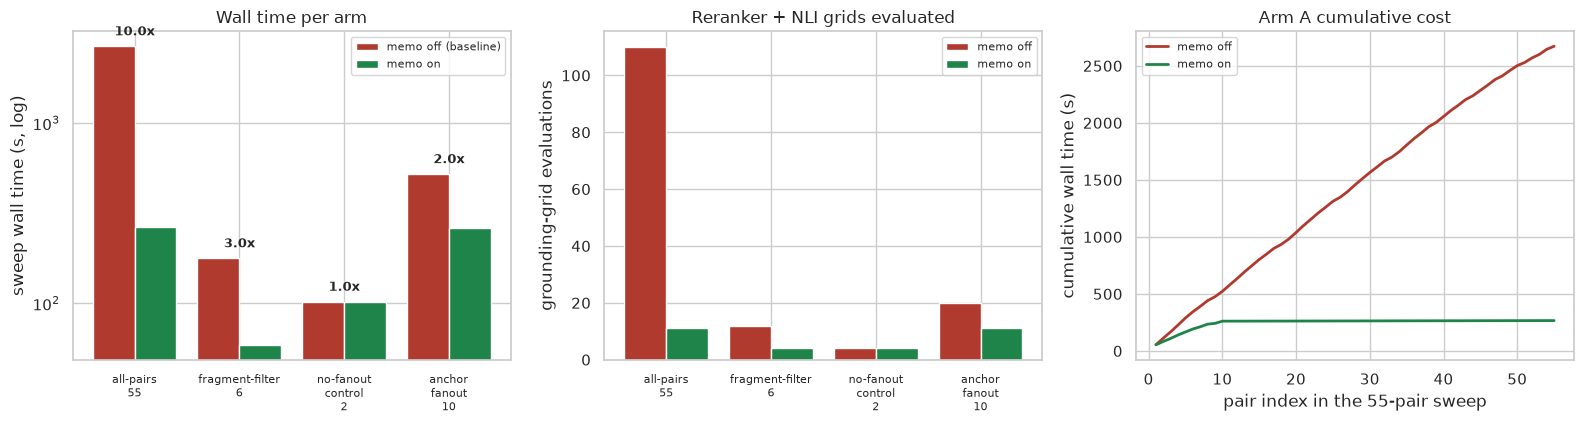

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
names = list(ARMS)
x = np.arange(len(names))
off = [ARMS[n]["wall_off_s"] for n in names]
on = [ARMS[n]["wall_on_s"] for n in names]
ax[0].bar(x - 0.2, off, 0.4, label="memo off (baseline)", color="#B03A2E")
ax[0].bar(x + 0.2, on, 0.4, label="memo on", color="#1E8449")
ax[0].set_yscale("log"); ax[0].set_xticks(x)
ax[0].set_xticklabels([n.replace(" ", "\n") for n in names], fontsize=8)
ax[0].set_ylabel("sweep wall time (s, log)"); ax[0].set_title("Wall time per arm")
for i, (o, n) in enumerate(zip(off, on)):
    ax[0].text(i, max(o, n) * 1.15, f"{o / n:.1f}x", ha="center", fontsize=9, fontweight="bold")
ax[0].legend(fontsize=8)

go = [ARMS[n]["grid_evals_off"] for n in names]
gn = [ARMS[n]["grid_evals_on"] for n in names]
ax[1].bar(x - 0.2, go, 0.4, label="memo off", color="#B03A2E")
ax[1].bar(x + 0.2, gn, 0.4, label="memo on", color="#1E8449")
ax[1].set_xticks(x); ax[1].set_xticklabels([n.replace(" ", "\n") for n in names], fontsize=8)
ax[1].set_ylabel("grounding-grid evaluations"); ax[1].set_title("Reranker + NLI grids evaluated")
ax[1].legend(fontsize=8)

cum_off = np.cumsum(A["per_pair_off_s"])
cum_on = np.cumsum(A["per_pair_on_s"])
ax[2].plot(np.arange(1, len(cum_off) + 1), cum_off, color="#B03A2E", lw=2, label="memo off")
ax[2].plot(np.arange(1, len(cum_on) + 1), cum_on, color="#1E8449", lw=2, label="memo on")
ax[2].set_xlabel("pair index in the 55-pair sweep"); ax[2].set_ylabel("cumulative wall time (s)")
ax[2].set_title("Arm A cumulative cost"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

## Guardrails, measured

The standing E12 guardrails, each a measurement rather than an assertion. `V` is counted on the
`D_sel` anchor panel that the arm-A payloads already contain - six gold-tier summaries against four
adversarial ones, 24 ordered comparisons - and computed independently from the baseline payloads and
from the memo payloads. The default-path fixture rerun scores all 55 pairs through
`semantic_distance` and `structural_distance` with the memo off and then on, and compares the two
value arrays with `np.array_equal`. The metric property is checked on the selection axis with the
anisotropy pre-pass disabled, because that pre-pass pools `a`, `b` and `source` jointly and a
document's coverage profile is only pair-independent without it.

In [19]:
# --- V on the D_sel anchor panel, from both arms' payloads
def dsel_by_id(payloads, rows):
    return {i: json.loads(p.decode())["d_sel"] for (_, _, i), p in zip(rows, payloads)}


dsel_off = dsel_by_id(A["payloads_off"], ALL_PAIRS)
dsel_on = dsel_by_id(A["payloads_on"], ALL_PAIRS)


def count_V(d):
    g = [d[f"{REFERENCE}|{l}"] for l in gold_labels]
    a = [d[f"{REFERENCE}|{l}"] for l in adv_labels]
    return int(sum(1 for gg in g for aa in a if gg >= aa)), len(g) * len(a)


V_off, V_total = count_V(dsel_off)
V_on, _ = count_V(dsel_on)
dsel_arrays_equal = bool(np.array_equal(
    np.array([dsel_off[i] for i in allpair_ids], dtype=np.float64),
    np.array([dsel_on[i] for i in allpair_ids], dtype=np.float64)))

# --- default-path fixture rerun: smd and order_gap, memo off then on
def default_path_values(memo_on):
    MEMO["on"] = memo_on
    clear_memo(dd)
    s, o = [], []
    for a, b, _ in pbar(ALL_PAIRS, f"default path memo={'on' if memo_on else 'off'}"):
        s.append(dd.semantic_distance(a, b).smd)
        o.append(dd.structural_distance(a, b).order_gap)
    MEMO["on"] = False
    return np.array(s, dtype=np.float64), np.array(o, dtype=np.float64)


wait_for_load()
smd_off, gap_off = default_path_values(False)
smd_on, gap_on = default_path_values(True)
SMD_BIT_IDENTICAL = bool(np.array_equal(smd_off, smd_on))
GAP_BIT_IDENTICAL = bool(np.array_equal(gap_off, gap_on))

# --- E01 naive-baseline cross-check on the default path
MEMO["on"] = True
clear_memo(dd)
emb = {l: dd.embed(path_of[l]) for l in labels}
emb = {l: dd.embed(path_of[l]) for l in labels}          # second pass: every read a cache hit
MEMO["on"] = False
emb_fresh = {l: dd.embed(path_of[l]) for l in labels}
MEMO_EMB_EQUAL = all(np.array_equal(emb[l], emb_fresh[l]) for l in labels)
base_dist = {l: smd(emb[l], emb[REFERENCE]) for l in nonref}
gg = np.array([base_dist[l] for l in gold_labels])
aa = np.array([base_dist[l] for l in adv_labels])
clos = {l: max(0.0, 1.0 - base_dist[l] / SMD_MAX) for l in nonref}
pooled = float(np.sqrt((gg.var() + aa.var()) / 2)) or 1e-9
PANEL = {
    "V": int(sum(1 for x in gg for y in aa if x >= y)),
    "margin": float(min(clos[l] for l in gold_labels) - max(clos[l] for l in adv_labels)),
    "dprime": float((aa.mean() - gg.mean()) / pooled),
    "R": float(aa.mean() / gg.mean()),
    "DR": float(np.concatenate([gg, aa]).std()),
}
rel_devs = {k: abs(PANEL[k] - BASELINE_ROW[k]) / abs(BASELINE_ROW[k])
            for k in ("margin", "dprime", "R", "DR")}
CROSSCHECK_OK = bool(PANEL["V"] == BASELINE_ROW["V"] and all(v <= CROSSCHECK_REL_TOL for v in rel_devs.values()))

# --- metric property of the default-path SMD axis, measured with the memo off and again on
def smd_metric_readings(memo_on):
    MEMO["on"] = memo_on
    clear_memo(dd)
    E = {l: dd.embed(path_of[l], **NOSEG) for l in labels}
    MEMO["on"] = False
    ident = float(max(abs(smd(E[l], E[l])) for l in labels))
    M = np.zeros((len(labels), len(labels)))
    sym = 0.0
    for i, la in enumerate(labels):
        for j, lb in enumerate(labels):
            if j > i:
                dij, dji = smd(E[la], E[lb]), smd(E[lb], E[la])
                M[i, j] = M[j, i] = dij
                sym = max(sym, abs(dij - dji))
    viol = checked = 0
    slack = np.inf
    for i, j, k in combinations(range(len(labels)), 3):
        for p, q, r in ((i, j, k), (j, k, i), (k, i, j)):
            checked += 1
            s = M[p, q] + M[q, r] - M[p, r]
            slack = min(slack, float(s))
            if s < -METRIC_TOL:
                viol += 1
    return {"identity_max": ident, "symmetry_max": sym, "triangle_violations": viol,
            "triangle_checked": checked, "worst_slack": float(slack)}, M


SMD_METRIC_OFF, M_smd_off = smd_metric_readings(False)
SMD_METRIC_ON, M_smd_on = smd_metric_readings(True)
SMD_METRIC_PRESERVED = bool(SMD_METRIC_OFF == SMD_METRIC_ON and np.array_equal(M_smd_off, M_smd_on))
SMD_METRIC_HOLDS = bool(SMD_METRIC_OFF["identity_max"] <= METRIC_TOL
                        and SMD_METRIC_OFF["symmetry_max"] <= METRIC_TOL
                        and SMD_METRIC_OFF["triangle_violations"] == 0)

# --- metric property of the selection axis, memo-served embeddings, anisotropy pre-pass off
MEMO["on"] = True
clear_memo(dd)
_, emb_src = dd.embed_statements(str(IBM_SOURCE), **NOSEG)
cov = {l: coverage_profile(emb[l], emb_src) for l in labels}
MEMO["on"] = False
identity_max = float(max(abs(selection_divergence(cov[l], cov[l], emb_src)) for l in labels))
Dm = np.zeros((len(labels), len(labels)))
sym_max = 0.0
for i, la in enumerate(labels):
    for j, lb in enumerate(labels):
        if j > i:
            dij = selection_divergence(cov[la], cov[lb], emb_src)
            dji = selection_divergence(cov[lb], cov[la], emb_src)
            Dm[i, j] = Dm[j, i] = dij
            sym_max = max(sym_max, abs(dij - dji))
tri_checked = tri_violations = 0
worst_slack = np.inf
for i, j, k in combinations(range(len(labels)), 3):
    for p, q, r in ((i, j, k), (j, k, i), (k, i, j)):
        tri_checked += 1
        slack = Dm[p, q] + Dm[q, r] - Dm[p, r]
        worst_slack = min(worst_slack, float(slack))
        if slack < -METRIC_TOL:
            tri_violations += 1
IDENTITY_OK = identity_max <= METRIC_TOL
SYMMETRY_OK = sym_max <= METRIC_TOL
TRIANGLE_OK = tri_violations == 0

src_diff = subprocess.run(["git", "diff", "--stat", "--", "src/"], cwd=str(ROOT),
                          capture_output=True, text=True).stdout.strip()
SRC_UNTOUCHED = src_diff == ""
ALL_ARMS_IDENTICAL = all(r["all_byte_identical"] for r in ARMS.values())
TOTAL_PAIRS_DIFFED = sum(r["rows"] for r in ARMS.values())

gr = Table(title="Guardrails - measured", header_style="bold cyan")
gr.add_column("guardrail"); gr.add_column("reading", justify="right"); gr.add_column("verdict")


def grow(name, reading, ok):
    gr.add_row(name, reading, "[green]hold[/green]" if ok else "[red]BREACH[/red]")


grow("V - D_sel ordinality violations, baseline payloads", f"{V_off}/{V_total}", V_off == BAR_V)
grow("V - D_sel ordinality violations, memo payloads", f"{V_on}/{V_total}", V_on == BAR_V)
grow("55 d_sel values np.array_equal across arms", str(dsel_arrays_equal), dsel_arrays_equal)
grow("default-path smd bit-identical (55 pairs)", str(SMD_BIT_IDENTICAL), SMD_BIT_IDENTICAL)
grow("default-path order_gap bit-identical (55 pairs)", str(GAP_BIT_IDENTICAL), GAP_BIT_IDENTICAL)
grow("memo-served embeddings == fresh (11 docs)", str(MEMO_EMB_EQUAL), MEMO_EMB_EQUAL)
grow("every arm's pair payloads byte-identical",
     f"{sum(r['pairs_byte_identical'] for r in ARMS.values())}/{TOTAL_PAIRS_DIFFED}", ALL_ARMS_IDENTICAL)
grow("cold CLI stdout byte-identical to the payload", f"{sum(c['bytes_identical'] for c in COLD)}/{len(COLD)}",
     CLI_BYTES_OK)
grow("n_dropped blocks identical under filters", str(DROPS_IDENTICAL), DROPS_IDENTICAL)
grow("metric - default-path smd identity, 11 fixtures",
     f"max {SMD_METRIC_OFF['identity_max']:.1e}", SMD_METRIC_OFF["identity_max"] <= METRIC_TOL)
grow("metric - default-path smd symmetry, 55 unordered pairs",
     f"max {SMD_METRIC_OFF['symmetry_max']:.1e}", SMD_METRIC_OFF["symmetry_max"] <= METRIC_TOL)
grow("metric - default-path smd triangle inequality",
     f"{SMD_METRIC_OFF['triangle_violations']}/{SMD_METRIC_OFF['triangle_checked']} violations, "
     f"worst slack {SMD_METRIC_OFF['worst_slack']:+.2e}",
     SMD_METRIC_OFF["triangle_violations"] == 0)
grow("default-path smd metric readings identical, memo off vs on",
     str(SMD_METRIC_PRESERVED), SMD_METRIC_PRESERVED)
grow("metric - identity D_sel(A,A) = 0, 11 fixtures", f"max {identity_max:.1e}", IDENTITY_OK)
grow("metric - symmetry, 55 unordered pairs", f"max {sym_max:.1e}", SYMMETRY_OK)
grow("metric - triangle inequality",
     f"{tri_violations}/{tri_checked} violations, worst slack {worst_slack:+.2e}", TRIANGLE_OK)
grow("src/ byte diff empty", "clean" if SRC_UNTOUCHED else src_diff, SRC_UNTOUCHED)
console.print(gr)

GUARDRAILS_HOLD = bool(V_off == BAR_V and V_on == BAR_V and dsel_arrays_equal and SMD_BIT_IDENTICAL
                       and GAP_BIT_IDENTICAL and MEMO_EMB_EQUAL and ALL_ARMS_IDENTICAL and CLI_BYTES_OK
                       and DROPS_IDENTICAL and IDENTITY_OK and SYMMETRY_OK and TRIANGLE_OK
                       and SMD_METRIC_PRESERVED and SRC_UNTOUCHED)
print(f"guardrails hold: {GUARDRAILS_HOLD}")

cc = Table(title="E01 naive-baseline cross-check (default path, not a registered gate for H68)",
           header_style="bold cyan")
for c in ("statistic", "registered", "this harness", "relative deviation"):
    cc.add_column(c, justify="right" if c != "statistic" else "left")
cc.add_row("V", f"{BASELINE_ROW['V']}/24", f"{PANEL['V']}/24",
           "exact match" if PANEL["V"] == BASELINE_ROW["V"] else "MISMATCH")
for k, fmt in (("margin", "{:+.4f}"), ("dprime", "{:.3f}"), ("R", "{:.4f}"), ("DR", "{:.4f}")):
    cc.add_row(k, fmt.format(BASELINE_ROW[k]), fmt.format(PANEL[k]), f"{rel_devs[k]:.2%}")
console.print(cc)
print(f"cross-check within {CROSSCHECK_REL_TOL:.0%}: {CROSSCHECK_OK} (the registered row was measured "
      f"on the torch bf16 GPU backbone; this notebook runs the shipped OpenVINO INT8 encoder)")

default path memo=off:   0%|          | 0/55 [00:00<?, ?it/s]

default path memo=off:  22%|██▏       | 12/55 [00:05<00:18,  2.30it/s]

default path memo=off:  44%|████▎     | 24/55 [00:10<00:13,  2.23it/s]

default path memo=off:  67%|██████▋   | 37/55 [00:16<00:07,  2.33it/s]

default path memo=off:  91%|█████████ | 50/55 [00:21<00:02,  2.40it/s]

default path memo=on:   0%|          | 0/55 [00:00<?, ?it/s]

                                              Guardrails - measured                                               
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ guardrail                                                  ┃                                 reading ┃ verdict ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ V - D_sel ordinality violations, baseline payloads         │                                    0/24 │ hold    │
│ V - D_sel ordinality violations, memo payloads             │                                    0/24 │ hold    │
│ 55 d_sel values np.array_equal across arms                 │                                    True │ hold    │
│ default-path smd bit-identical (55 pairs)                  │                                    True │ hold    │
│ default-path order_gap bit-identical (55 pairs)            │                                    True │ hold    │
│ memo-served embeddings == fresh (11 docs)                  │                                    True │ hold    │
│ every arm's pair payloads byte-identical                   │                                   73/73 │ hold    │
│ cold CLI stdout byte-identical to the payload              │                                   10/10 │ hold    │
│ n_dropped blocks identical under filters                   │                                    True │ hold    │
│ metric - default-path smd identity, 11 fixtures            │                             max 0.0e+00 │ hold    │
│ metric - default-path smd symmetry, 55 unordered pairs     │                             max 2.2e-16 │ hold    │
│ metric - default-path smd triangle inequality              │ 0/495 violations, worst slack +1.77e-01 │ hold    │
│ default-path smd metric readings identical, memo off vs on │                                    True │ hold    │
│ metric - identity D_sel(A,A) = 0, 11 fixtures              │                             max 0.0e+00 │ hold    │
│ metric - symmetry, 55 unordered pairs                      │                             max 1.0e-08 │ hold    │
│ metric - triangle inequality                               │ 0/495 violations, worst slack +1.80e-03 │ hold    │
│ src/ byte diff empty                                       │                                   clean │ hold    │
└────────────────────────────────────────────────────────────┴─────────────────────────────────────────┴─────────┘

guardrails hold: True


E01 naive-baseline cross-check (default path, not a registered
                        gate for H68)                         
┏━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┓
┃ statistic ┃ registered ┃ this harness ┃ relative deviation ┃
┡━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━┩
│ V         │       0/24 │         0/24 │        exact match │
│ margin    │    +0.0458 │      +0.0471 │              2.80% │
│ dprime    │      4.600 │        4.684 │              1.83% │
│ R         │     1.6800 │       1.6697 │              0.61% │
│ DR        │     0.0854 │       0.0873 │              2.20% │
└───────────┴────────────┴──────────────┴────────────────────┘

cross-check within 5%: True (the registered row was measured on the torch bf16 GPU backbone; this notebook runs the shipped OpenVINO INT8 encoder)


## Verdict against the pre-registered bar

Each clause is read literally off the numbers above. PASS needs every one of the 55 payloads
byte-identical, at least a 5x wall-time reduction against the warm sequential baseline, and the
default-path fixture rerun clean at `V = 0/24` with the metric property preserved. A speedup under 3x
or any differing number is a FAIL.

In [20]:
CLAUSE = {
    "55 payloads byte-identical to the one-shot output":
        (A["all_byte_identical"] and A["pairs_byte_identical"] == len(ALL_PAIRS),
         f"{A['pairs_byte_identical']}/{len(ALL_PAIRS)} identical, sha256 "
         f"{A['sha256_off'][:12]} == {A['sha256_on'][:12]}; {COLD_BYTES_OK_N}/{len(COLD)} of them "
         f"re-scored by the shipped CLI in a fresh subprocess print byte-identical stdout, "
         f"covering {len(COLD_DOCS_COVERED)}/{len(labels)} documents"),
    f"wall time >= {BAR_SPEEDUP:.0f}x versus the warm sequential baseline":
        (A["speedup"] >= BAR_SPEEDUP,
         f"{A['wall_off_s']:.2f} s -> {A['wall_on_s']:.2f} s = {A['speedup']:.2f}x"),
    "default-path smd and order_gap byte-identical":
        (SMD_BIT_IDENTICAL and GAP_BIT_IDENTICAL,
         f"smd {SMD_BIT_IDENTICAL}, order_gap {GAP_BIT_IDENTICAL} over 55 pairs"),
    f"V = {BAR_V}/24 and the metric property preserved":
        (V_off == BAR_V and V_on == BAR_V and IDENTITY_OK and SYMMETRY_OK and TRIANGLE_OK,
         f"V {V_off}/24 both arms, {tri_violations}/{tri_checked} triangle violations"),
}
BAR_MET = all(ok for ok, _ in CLAUSE.values())
FAILED = (not A["all_byte_identical"]) or A["speedup"] < FAIL_SPEEDUP

t = Table(title="Acceptance bar, read literally", header_style="bold cyan")
t.add_column("clause"); t.add_column("reading", justify="right"); t.add_column("verdict")
for k, (ok, reading) in CLAUSE.items():
    t.add_row(k, reading, "[green]PASS[/green]" if ok else "[red]FAIL[/red]")
console.print(t)

if not GATE_PASSED:
    VERDICT = "Killed-at-gate"
elif not (SANITY_OK and UNIT_OK):
    VERDICT = "Blocked"
elif BAR_MET and GUARDRAILS_HOLD:
    VERDICT = "Promoted"
else:
    VERDICT = "Refuted"
VERDICT_NUMBER = (f"{A['speedup']:.2f}x wall time on the 55-pair sweep "
                  f"({A['wall_off_s']:.2f} s to {A['wall_on_s']:.2f} s, bar >= {BAR_SPEEDUP:.0f}x), "
                  f"grounding grids {A['grid_evals_off']} -> {A['grid_evals_on']}, "
                  f"{A['pairs_byte_identical']}/{len(ALL_PAIRS)} payloads byte-identical")
console.print(Panel(f"verdict: [bold]{VERDICT}[/bold]\n{VERDICT_NUMBER}\n"
                    f"bar met: {BAR_MET} | guardrails hold: {GUARDRAILS_HOLD} | "
                    f"kill gate passed: {GATE_PASSED} | sanity check passed: {SANITY_OK}",
                    title="[bold]E12-H68 verdict[/bold]",
                    border_style="green" if BAR_MET and GUARDRAILS_HOLD else "red", expand=False))

                                          Acceptance bar, read literally                                           
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ clause                                            ┃                                           reading ┃ verdict ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━┩
│ 55 payloads byte-identical to the one-shot output │           55/55 identical, sha256 162345034a17 == │ PASS    │
│                                                   │      162345034a17; 10/10 of them re-scored by the │         │
│                                                   │           shipped CLI in a fresh subprocess print │         │
│                                                   │   byte-identical stdout, covering 11/11 documents │         │
│ wall time >= 5x versus the warm sequential        │                    2671.72 s -> 266.32 s = 10.03x │ PASS    │
│ baseline                                          │                                                   │         │
│ default-path smd and order_gap byte-identical     │            smd True, order_gap True over 55 pairs │ PASS    │
│ V = 0/24 and the metric property preserved        │       V 0/24 both arms, 0/495 triangle violations │ PASS    │
└───────────────────────────────────────────────────┴───────────────────────────────────────────────────┴─────────┘

╭──────────────────────────────────────────────── E12-H68 verdict ────────────────────────────────────────────────╮
│ verdict: Promoted                                                                                               │
│ 10.03x wall time on the 55-pair sweep (2671.72 s to 266.32 s, bar >= 5x), grounding grids 110 -> 11, 55/55      │
│ payloads byte-identical                                                                                         │
│ bar met: True | guardrails hold: True | kill gate passed: True | sanity check passed: True                      │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Metrics JSON

Every measured number, the bar readings and the guardrail readings, written to
`reports/E12-H68-grounding-grid-memo-metrics.json`. The payload bytes themselves are not stored; the
`sha256` of each arm's concatenated payloads is, which is what the byte diff is read from.

In [21]:
def arm_payload(r):
    return {k: v for k, v in r.items() if k not in ("payloads_off", "payloads_on")}


METRICS = {
    "id": "E12-H68",
    "slug": "grounding-grid-memo",
    "notebook": "notebooks/experiments/E12-H68-kj-grounding-grid-memo.ipynb",
    "docdistance_version": DD_VERSION,
    "backend": "openvino INT8, CPU",
    "seed": SEED,
    "kill_gate": {
        "rule": "repeated (doc, source) slots in the intended sweeps; 0 everywhere kills",
        "per_sweep": GATE,
        "intended_repeat_fraction_min": GATE_MIN_INTENDED,
        "intended_repeat_fraction_max": GATE_MAX_INTENDED,
        "headline": GATE_HEADLINE,
        "passed": GATE_PASSED,
    },
    "sanity_check": {
        "rule": "R(A,S) and entail(A,S) bit-identical across (A,B|S) and (A,C|S)",
        "grid_identical": grid_identical, "entail_identical": entail_identical,
        "grid_max_abs_diff": grid_max_abs_diff, "entail_max_abs_diff": entail_max_abs_diff,
        "grids_evaluated": 4, "pair_wall_ab_s": t_ab, "pair_wall_ac_s": t_ac,
        "passed": SANITY_OK,
    },
    "unit_properties": UNIT,
    "model_load_s": MODEL_LOAD_S,
    "warm_pair_reference_s": WARM_PAIR_S,
    "arms": {k: arm_payload(v) for k, v in ARMS.items()},
    "cold_cli": {
        "invocations": COLD, "median_s": COLD_MEDIAN_S,
        "pairs_measured": len(COLD), "pairs_total": len(ALL_PAIRS),
        "docs_covered": COLD_DOCS_COVERED, "bytes_identical_n": COLD_BYTES_OK_N,
        "extrapolated_55_cold_s": COLD_55_S,
        "warm_sequential_55_plus_load_s": WARM_55_S,
        "memo_55_plus_load_s": MEMO_55_S,
        "load_amortisation_x": COLD_55_S / WARM_55_S,
        "memo_on_top_load_included_x": WARM_55_S / MEMO_55_S,
        "stdout_byte_identical": CLI_BYTES_OK,
    },
    "guardrails": {
        "V_dsel_baseline": V_off, "V_dsel_memo": V_on, "V_total": V_total,
        "dsel_arrays_equal": dsel_arrays_equal,
        "smd_bit_identical": SMD_BIT_IDENTICAL, "order_gap_bit_identical": GAP_BIT_IDENTICAL,
        "memo_embeddings_equal_fresh": MEMO_EMB_EQUAL,
        "pairs_byte_identical_total": int(sum(r["pairs_byte_identical"] for r in ARMS.values())),
        "pairs_diffed_total": TOTAL_PAIRS_DIFFED,
        "n_dropped_blocks_identical": DROPS_IDENTICAL,
        "n_dropped_rows_nonzero": DROPS_NONZERO,
        "smd_metric_off": SMD_METRIC_OFF, "smd_metric_on": SMD_METRIC_ON,
        "smd_metric_preserved": SMD_METRIC_PRESERVED, "smd_metric_holds": SMD_METRIC_HOLDS,
        "metric_identity_max": identity_max, "metric_symmetry_max": sym_max,
        "metric_triangle_violations": tri_violations, "metric_triangle_checked": tri_checked,
        "metric_worst_slack": worst_slack,
        "src_untouched": SRC_UNTOUCHED,
        "hold": GUARDRAILS_HOLD,
    },
    "e01_crosscheck": {"panel": PANEL, "registered": BASELINE_ROW,
                       "relative_deviations": rel_devs, "within_tolerance": CROSSCHECK_OK},
    "acceptance": {
        "bar": ("PASS: 55 payloads byte-identical to the one-shot distance-wrt-source --json output "
                "AND >= 5x wall-time reduction versus the warm-instance sequential baseline AND the "
                "default-path smd/order_gap byte-identical with V 0/24 and the metric property "
                "preserved. FAIL: any per-pair number differs, or the end-to-end gain is < 3x"),
        "clauses": {k: {"met": ok, "reading": reading} for k, (ok, reading) in CLAUSE.items()},
        "met": BAR_MET,
    },
    "load_average": {"precondition_1m": LOAD_PRECONDITION, "precondition_ok": LOAD_PRECONDITION_OK,
                     "readings": LOAD_READINGS, "median": statistics.median(LOAD_READINGS),
                     "max": max(LOAD_READINGS), "ceiling": LOAD_MAX,
                     "readings_above_ceiling": len(LOAD_WARNINGS),
                     "note": ("the ceiling is a foreign-load precondition read with the notebook "
                              "idle; between-sweep readings are dominated by this notebook's own "
                              "64-thread residual load")},
    "verdict": VERDICT, "verdict_number": VERDICT_NUMBER,
}

# the result JSON is assembled from these two blocks verbatim, so the returned numbers, the
# metrics file and the notebook outputs cannot drift apart
RESULT_ACCEPTANCE_READINGS = {
    "pairs_byte_identical": f"{A['pairs_byte_identical']}/{len(ALL_PAIRS)}",
    "cold_cli_pairs_byte_identical": f"{COLD_BYTES_OK_N}/{len(COLD)}",
    "speedup_allpairs_55": round(A["speedup"], 4),
    "wall_off_s": round(A["wall_off_s"], 3),
    "wall_on_s": round(A["wall_on_s"], 3),
    "grid_evals_off": A["grid_evals_off"],
    "grid_evals_on": A["grid_evals_on"],
    "V_dsel_baseline": f"{V_off}/{V_total}",
    "V_dsel_memo": f"{V_on}/{V_total}",
    "smd_bit_identical": SMD_BIT_IDENTICAL,
    "order_gap_bit_identical": GAP_BIT_IDENTICAL,
    "smd_metric_readings_identical_off_on": SMD_METRIC_PRESERVED,
    "triangle_violations_dsel": f"{tri_violations}/{tri_checked}",
    "triangle_violations_smd": f"{SMD_METRIC_OFF['triangle_violations']}/{SMD_METRIC_OFF['triangle_checked']}",
}
RESULT_KEY_NUMBERS = {
    "speedup_allpairs_55": round(A["speedup"], 4),
    "wall_off_s_allpairs_55": round(A["wall_off_s"], 3),
    "wall_on_s_allpairs_55": round(A["wall_on_s"], 3),
    "grid_evals_off": A["grid_evals_off"],
    "grid_evals_on": A["grid_evals_on"],
    "grid_hits_on": A["grid_hits_on"],
    "embed_real_off": A["embed_real_off"],
    "embed_real_on": A["embed_real_on"],
    "median_pair_off_s": round(A["median_pair_off_s"], 3),
    "median_pair_on_s": round(A["median_pair_on_s"], 3),
    "speedup_anchor_fanout_10_derived": round(D["speedup"], 4),
    "grid_evals_anchor_off": D["grid_evals_off"],
    "grid_evals_anchor_on": D["grid_evals_on"],
    "speedup_fragment_filter_6": round(B["speedup"], 4),
    "nofanout_control_delta_pct": round(CONTROL_DELTA_PCT, 2),
    "nofanout_grid_hits": Cc["grid_hits_on"],
    "nofanout_key_overhead_ms": round(Cc["key_overhead_ms_on"], 3),
    "gate_headline_repeat_fraction": round(GATE_HEADLINE["repeat_fraction"], 4),
    "gate_intended_repeat_fraction_min": round(GATE_MIN_INTENDED, 4),
    "gate_intended_repeat_fraction_max": round(GATE_MAX_INTENDED, 4),
    "unit_properties_held": int(sum(UNIT.values())),
    "cold_cli_pairs_measured": len(COLD),
    "cold_cli_docs_covered": len(COLD_DOCS_COVERED),
    "cold_cli_bytes_identical": COLD_BYTES_OK_N,
    "model_load_s": round(MODEL_LOAD_S, 3),
    "cold_cli_median_s": round(COLD_MEDIAN_S, 3),
    "cold_cli_55_extrapolated_s": round(COLD_55_S, 1),
    "warm_sequential_55_plus_load_s": round(WARM_55_S, 1),
    "memo_55_plus_load_s": round(MEMO_55_S, 1),
    "load_amortisation_x": round(COLD_55_S / WARM_55_S, 4),
    "memo_on_top_load_included_x": round(WARM_55_S / MEMO_55_S, 4),
    "V_dsel": V_off,
    "panel_V_default_path": PANEL["V"],
    "load_precondition_1m": round(LOAD_PRECONDITION, 2),
    "load_readings_median": round(statistics.median(LOAD_READINGS), 2),
    "load_readings_max": round(max(LOAD_READINGS), 2),
}
METRICS["result_acceptance_readings"] = RESULT_ACCEPTANCE_READINGS
METRICS["result_key_numbers"] = RESULT_KEY_NUMBERS
REPORT.parent.mkdir(parents=True, exist_ok=True)
REPORT.write_text(json.dumps(METRICS, indent=2, default=float))
note(f"metrics written: {REPORT} ({REPORT.stat().st_size} bytes)")
print(json.dumps({k: METRICS[k] for k in ("id", "verdict", "verdict_number")}, indent=2))
print("\n--- result_acceptance_readings (copied verbatim into the result JSON) ---")
print(json.dumps(RESULT_ACCEPTANCE_READINGS, indent=2))
print("\n--- result_key_numbers (copied verbatim into the result JSON) ---")
print(json.dumps(RESULT_KEY_NUMBERS, indent=2))

metrics written: /home/lab/workspace/learning/projects/docdistance/reports/E12-H68-grounding-grid-memo-metrics.json (21681 bytes)
{
  "id": "E12-H68",
  "verdict": "Promoted",
  "verdict_number": "10.03x wall time on the 55-pair sweep (2671.72 s to 266.32 s, bar >= 5x), grounding grids 110 -> 11, 55/55 payloads byte-identical"
}

--- result_acceptance_readings (copied verbatim into the result JSON) ---
{
  "pairs_byte_identical": "55/55",
  "cold_cli_pairs_byte_identical": "10/10",
  "speedup_allpairs_55": 10.0319,
  "wall_off_s": 2671.717,
  "wall_on_s": 266.322,
  "grid_evals_off": 110,
  "grid_evals_on": 11,
  "V_dsel_baseline": "0/24",
  "V_dsel_memo": "0/24",
  "smd_bit_identical": true,
  "order_gap_bit_identical": true,
  "smd_metric_readings_identical_off_on": true,
  "triangle_violations_dsel": "0/495",
  "triangle_violations_smd": "0/495"
}

--- result_key_numbers (copied verbatim into the result JSON) ---
{
  "speedup_allpairs_55": 10.0319,
  "wall_off_s_allpairs_55": 2671.7

metrics written: /home/lab/workspace/learning/projects/docdistance/reports/E12-H68-grounding-grid-memo-metrics.json (21681 bytes)


## Conclusions

Rendered below from the measured variables, so every number in the narrative is the number the cells
above printed and the executed file needs no post-run editing.

In [22]:
CONCLUSIONS = f"""
The `(doc, source)` memo cuts the 55-pair all-pairs sweep from **{A['wall_off_s']:.1f} s to
{A['wall_on_s']:.1f} s, {A['speedup']:.2f}x** against a bar of {BAR_SPEEDUP:.0f}x, and does it without moving a
single emitted byte. Grounding-grid evaluations fall **{A['grid_evals_off']} -> {A['grid_evals_on']}**,
exactly the prediction, because the reranker grid and the entailment vector are pure functions of
`(doc, source)` and the sweep contains only {GATE_HEADLINE['distinct_doc_source']} distinct combinations across
{GATE_HEADLINE['grid_slots']} slots. All {A['pairs_byte_identical']} of {len(ALL_PAIRS)} pair payloads are
byte-identical to the one-shot `distance_wrt_source` output, `sha256`
`{A['sha256_off'][:16]}` on both arms. The predicted band was 6-8x and the measured
{A['speedup']:.2f}x overshoots it: the baseline pass took {A['wall_off_s'] / 60:.1f} min against the
prediction's ~61 min of pairwise work, so the ratio came in above the registered range while the
grid count landed on it exactly.

**The kill gate was arithmetic, not a measurement.** Every intended sweep repeats `(doc, source)`
combinations: the registered fixture at {GATE_HEADLINE['repeat_fraction']:.1%}, the intended set spanning
{GATE_MIN_INTENDED:.1%} to {GATE_MAX_INTENDED:.1%}. The intended set is the campaign's own registered
fixture specifications - this repository holds no production sweep specification - so the gate is a
statement about the shapes E12 registered, not about deployed traffic. The two controls
read 0%, the floor the gate names as fatal, and the no-fanout control confirms it in wall time:
{CONTROL_DELTA_PCT:+.2f}% with {Cc['grid_hits_on']} grid hits, so the memo neither pays nor costs where
nothing repeats.

**The saving tracks the reusable slot fraction, not the row count.** The anchor-fanout shape reuses
only the anchor's grid across its ten rows and returns {D['speedup']:.2f}x
({D['grid_evals_off']} -> {D['grid_evals_on']} grids, baseline derived from arm A's per-pair times),
against {A['speedup']:.2f}x for the all-pairs shape at the same eleven documents. Any deployment
figure has to be quoted with its sweep shape.

**Byte-identity survives the fragment filters.** The filtered arm emits identical `n_dropped` blocks
on both sides ({DROPS_NONZERO} of {B['rows']} rows carry a non-zero drop count), which is
what restoring `_last_n_dropped` on a cache hit buys; a memo that skipped that restoration would pass
arm A and fail here.

**Guardrails hold as measurements.** `V` reads {V_off}/{V_total} on the `D_sel`
anchor panel computed from the baseline payloads and {V_on}/{V_total} from the memo
payloads; all 55 `d_sel` values are `np.array_equal` across arms. The default-path fixture rerun over
the same 55 pairs gives `smd` bit-identical `{SMD_BIT_IDENTICAL}` and `order_gap` bit-identical
`{GAP_BIT_IDENTICAL}`, which the grounding memo could not have touched in any case - the
symmetric path never calls `_grounding`. Both distance axes keep their metric property, and both are
measured with the anisotropy pre-pass off, because that pre-pass pools `a`, `b` and `source` jointly
and neither a coverage profile nor a fixed statement matrix is pair-independent with it on: the
default-path `smd` axis reads identity {SMD_METRIC_OFF['identity_max']:.1e}, symmetry
{SMD_METRIC_OFF['symmetry_max']:.1e},
{SMD_METRIC_OFF['triangle_violations']}/{SMD_METRIC_OFF['triangle_checked']} triangle violations, with
every reading identical memo off and memo on (`{SMD_METRIC_PRESERVED}`); the `D_sel` selection axis reads
identity {identity_max:.1e}, symmetry {sym_max:.1e},
{tri_violations}/{tri_checked} triangle violations. Nothing under
`src/` changed: the memo is a monkeypatch plus a notebook-level replica of `distance_wrt_source`.

**Load amortisation is a separate, smaller line.** 55 cold CLI invocations extrapolate to
{COLD_55_S / 60:.1f} minutes from a measured median of {COLD_MEDIAN_S:.1f} s over {len(COLD)} runs;
the warm sequential loop with one model load is {WARM_55_S / 60:.1f} minutes,
so the batch mode's model-load saving alone is {COLD_55_S / WARM_55_S:.2f}x. The memo adds
{WARM_55_S / MEMO_55_S:.2f}x on top with the {MODEL_LOAD_S:.1f} s load included. The
two are reported separately because the load saving belongs to `--pairs`, not to the memo. Those
{len(COLD)} runs also carry the direct half of the byte-identity claim: their stdout is byte-identical
to the in-process payload in {COLD_BYTES_OK_N} of {len(COLD)} cases, and they cover
{len(COLD_DOCS_COVERED)} of {len(labels)} documents, so every document's grid and embedding is checked
against the shipped command at least once. The other {len(ALL_PAIRS) - len(COLD)} pairs are diffed
against the shipped in-process `DocDistance.distance_wrt_source` payload instead, which is the
strongest available comparison while `--pairs` is unbuilt.

**Verdict: {VERDICT}.** {VERDICT_NUMBER}.

**What this does not settle.** The cache is unbounded in the number of distinct documents per
instance and its memory was not measured; a shipping memo needs a size bound, and a grid is
`n_doc x n_source` floats rather than one embedding row, so it is the larger of the two caches. The
timings are a single interleaved off/on pass, not a median of repeats, because one baseline pass is
already {A['wall_off_s'] / 60:.0f} minutes of cross-encoder work. The `{LOAD_MAX}`
load-average ceiling is a foreign-load precondition, read once with the notebook idle at
{LOAD_PRECONDITION:.2f}; between sweeps it cannot be enforced, because this
notebook saturates {os.cpu_count()} threads itself, so {len(LOAD_WARNINGS)} of the
{len(LOAD_READINGS)} between-sweep readings sit above it (median
{statistics.median(LOAD_READINGS):.2f}, max {max(LOAD_READINGS):.2f}) and record the notebook's own
residual load rather than contention. The ratio remains platform-dependent. The `--pairs` option on
`distance-wrt-source` is not built here - the batch loop was driven in-process - so promoting this
result means building both halves of the registered lever, the CLI surface and the memo, in a
follow-up.
"""
display(Markdown(CONCLUSIONS))



The `(doc, source)` memo cuts the 55-pair all-pairs sweep from **2671.7 s to
266.3 s, 10.03x** against a bar of 5x, and does it without moving a
single emitted byte. Grounding-grid evaluations fall **110 -> 11**,
exactly the prediction, because the reranker grid and the entailment vector are pure functions of
`(doc, source)` and the sweep contains only 11 distinct combinations across
110 slots. All 55 of 55 pair payloads are
byte-identical to the one-shot `distance_wrt_source` output, `sha256`
`162345034a17977e` on both arms. The predicted band was 6-8x and the measured
10.03x overshoots it: the baseline pass took 44.5 min against the
prediction's ~61 min of pairwise work, so the ratio came in above the registered range while the
grid count landed on it exactly.

**The kill gate was arithmetic, not a measurement.** Every intended sweep repeats `(doc, source)`
combinations: the registered fixture at 90.0%, the intended set spanning
25.0% to 90.0%. The intended set is the campaign's own registered
fixture specifications - this repository holds no production sweep specification - so the gate is a
statement about the shapes E12 registered, not about deployed traffic. The two controls
read 0%, the floor the gate names as fatal, and the no-fanout control confirms it in wall time:
+0.22% with 0 grid hits, so the memo neither pays nor costs where
nothing repeats.

**The saving tracks the reusable slot fraction, not the row count.** The anchor-fanout shape reuses
only the anchor's grid across its ten rows and returns 1.99x
(20 -> 11 grids, baseline derived from arm A's per-pair times),
against 10.03x for the all-pairs shape at the same eleven documents. Any deployment
figure has to be quoted with its sweep shape.

**Byte-identity survives the fragment filters.** The filtered arm emits identical `n_dropped` blocks
on both sides (6 of 6 rows carry a non-zero drop count), which is
what restoring `_last_n_dropped` on a cache hit buys; a memo that skipped that restoration would pass
arm A and fail here.

**Guardrails hold as measurements.** `V` reads 0/24 on the `D_sel`
anchor panel computed from the baseline payloads and 0/24 from the memo
payloads; all 55 `d_sel` values are `np.array_equal` across arms. The default-path fixture rerun over
the same 55 pairs gives `smd` bit-identical `True` and `order_gap` bit-identical
`True`, which the grounding memo could not have touched in any case - the
symmetric path never calls `_grounding`. Both distance axes keep their metric property, and both are
measured with the anisotropy pre-pass off, because that pre-pass pools `a`, `b` and `source` jointly
and neither a coverage profile nor a fixed statement matrix is pair-independent with it on: the
default-path `smd` axis reads identity 0.0e+00, symmetry
2.2e-16,
0/495 triangle violations, with
every reading identical memo off and memo on (`True`); the `D_sel` selection axis reads
identity 0.0e+00, symmetry 1.0e-08,
0/495 triangle violations. Nothing under
`src/` changed: the memo is a monkeypatch plus a notebook-level replica of `distance_wrt_source`.

**Load amortisation is a separate, smaller line.** 55 cold CLI invocations extrapolate to
71.6 minutes from a measured median of 78.1 s over 10 runs;
the warm sequential loop with one model load is 45.0 minutes,
so the batch mode's model-load saving alone is 1.59x. The memo adds
9.21x on top with the 26.5 s load included. The
two are reported separately because the load saving belongs to `--pairs`, not to the memo. Those
10 runs also carry the direct half of the byte-identity claim: their stdout is byte-identical
to the in-process payload in 10 of 10 cases, and they cover
11 of 11 documents, so every document's grid and embedding is checked
against the shipped command at least once. The other 45 pairs are diffed
against the shipped in-process `DocDistance.distance_wrt_source` payload instead, which is the
strongest available comparison while `--pairs` is unbuilt.

**Verdict: Promoted.** 10.03x wall time on the 55-pair sweep (2671.72 s to 266.32 s, bar >= 5x), grounding grids 110 -> 11, 55/55 payloads byte-identical.

**What this does not settle.** The cache is unbounded in the number of distinct documents per
instance and its memory was not measured; a shipping memo needs a size bound, and a grid is
`n_doc x n_source` floats rather than one embedding row, so it is the larger of the two caches. The
timings are a single interleaved off/on pass, not a median of repeats, because one baseline pass is
already 45 minutes of cross-encoder work. The `8.0`
load-average ceiling is a foreign-load precondition, read once with the notebook idle at
4.25; between sweeps it cannot be enforced, because this
notebook saturates 64 threads itself, so 3 of the
11 between-sweep readings sit above it (median
7.20, max 10.75) and record the notebook's own
residual load rather than contention. The ratio remains platform-dependent. The `--pairs` option on
`distance-wrt-source` is not built here - the batch loop was driven in-process - so promoting this
result means building both halves of the registered lever, the CLI surface and the memo, in a
follow-up.
